# Active Future Labs | NASA Earth Trends Backend

**NASA Space Apps Challenge 2026 · Data collection, statistical analysis and frontend API**

This notebook runs the data side of our Earth System Trend Detective project. It retrieves observations from NASA services, combines ten environmental variables across 360 defined study areas, calculates historical trends, and exposes the results to our frontend through a Python API.

**What this notebook uses:** NASA POWER, GLDAS, GPM IMERG and MERRA-2. It does **not** read Luke's CSV or invent any environmental measurements. Our observations come from live NASA requests and are cached in SQLite so the application doesn't download the archive each time someone opens a chart.

Our study areas are **rectangles on a map**, not official countries or ecological regions. We aim to analyse January 2000 to December 2024 (300 months). Genuine gaps are kept as missing values. A successful run must be checked for coverage before any scientific conclusions are published.

### How to use it

Run the cells in order. On the first run, you will approve Google Drive access and sign in to NASA Earthdata to download the protected products. The notebook will save completed observations in a database on Drive and resume from that database when you return. The dashboard itself will not ask visitors to sign in to NASA.

The full data download is substantial. The first requests act as live checks; the collection section then processes the remaining areas and months in batches. If an API returns an error, the notebook keeps completed work and reports where it stopped rather than silently substituting data.

**Before sharing this notebook publicly:** clear the Earthdata login cell's output and check that no tokens or personal information have been saved. Google Colab is for development, not permanent API hosting.

## 1. Prepare the Colab environment

Install the libraries for NASA downloads, monthly data processing, statistical modelling and the FastAPI server. Colab already provides some of these packages, but this cell keeps the setup reproducible. If Colab asks for a runtime restart, restart once and rerun the notebook from the top.

In [ ]:
%pip -q install "requests>=2.31" "numpy>=1.26" "pandas>=2.1" "scipy>=1.11" "statsmodels>=0.14" "fastapi>=0.110" "uvicorn>=0.27" "httpx>=0.25" "xarray>=2024.1" "h5py>=3.9" "netCDF4>=1.6" "earthaccess>=0.14" "pyngrok>=7.0" "pytest>=8.0"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 4.8.5 requires fsspec[http]<=2026.2.0,>=2023.1.0, but you have fsspec 2026.9.0 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2026.9.0 which is incompatible.


## 2. Connect Google Drive so our work is saved

Colab's local files disappear when the runtime resets. We therefore keep a copy of the SQLite database in **My Drive / active_future_labs**. On a new session, the notebook restores that copy before collecting anything else.

No CSV upload is required. The database is created from NASA API responses.

In [ ]:
from pathlib import Path
import json
import logging
import shutil
import sqlite3
import sys
import time

from google.colab import drive

drive.mount('/content/drive')

PROJECT = Path('/content/active_future_labs')
PROJECT.mkdir(parents=True, exist_ok=True)

PERSIST = Path('/content/drive/MyDrive/active_future_labs')
PERSIST.mkdir(parents=True, exist_ok=True)
BACKUP_PATH = PERSIST / 'nasa_cache.sqlite3'
DB = PROJECT / 'nasa_cache.sqlite3'

# Restore our last saved observations after a fresh Colab session.
if not DB.exists() and BACKUP_PATH.exists():
    shutil.copy2(BACKUP_PATH, DB)
    print('Restored database from Google Drive.')
else:
    print('Using local database:', DB)

if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))

logging.basicConfig(level=logging.INFO, format='%(levelname)s: %(message)s')

Mounted at /content/drive
Using local database: /content/active_future_labs/nasa_cache.sqlite3


## 3. Set up the Python backend

This cell writes the backend module that handles NASA requests, spatial aggregation, SQLite storage, trend modelling and the JSON endpoints used by the website.

The module is included inside the notebook so the project can run from a single `.ipynb` file. We also keep a standalone `backend.py` in the project package for GitHub and deployment.

In [ ]:
%%writefile /content/active_future_labs/backend.py
"""NASA data and statistics for the Active Future Labs dashboard.

Data always comes from NASA services. The collector does not import another
team member's dataset, create sample measurements, or fill missing values.

The 360 geographical selections are rectangular study areas rather than
countries. Where NASA POWER cannot return a native regional grid, nine real
point requests are used as an explicitly labelled approximation.

This module runs inside Google Colab for collection and testing. The same
backend can later be deployed on a persistent server for the frontend.
"""
from __future__ import annotations

import calendar
import json
import logging
import math
import sqlite3
import tempfile
import time
from dataclasses import dataclass
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import requests
from scipy.stats import t as student_t
from statsmodels.stats.multitest import multipletests
import statsmodels.api as sm
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

log = logging.getLogger(__name__)
POWER_URL = 'https://power.larc.nasa.gov/api/temporal/monthly/regional'
POINT_URL = 'https://power.larc.nasa.gov/api/temporal/monthly/point'
POWER = ('T2M', 'PRECTOTCORR', 'RH2M', 'GWETTOP')
GLDAS = ('soil_moisture', 'evaporation', 'runoff')
IMERG = ('gpm_rain',)
AEROSOL = ('aerosol', 'dust')
VARIABLES = POWER + GLDAS + IMERG + AEROSOL
UNITS = {
    'T2M':'°C', 'PRECTOTCORR':'mm/day', 'RH2M':'%', 'GWETTOP':'fraction',
    'soil_moisture':'kg/m² (0–10 cm)', 'evaporation':'mm/day',
    'runoff':'mm/day', 'gpm_rain':'mm/day',
    'aerosol':'dimensionless AOD', 'dust':'dimensionless AOD'
}
SOURCE = {v:'NASA POWER (MERRA-2 derived)' for v in POWER}
SOURCE.update({v:'NASA GLDAS_NOAH025_M 2.1' for v in GLDAS})
SOURCE.update({v:'NASA GPM_3IMERGM V07' for v in IMERG})
SOURCE.update({v:'NASA M2TMNXAER 5.12.4' for v in AEROSOL})
PRODUCTS = {
    'gldas': dict(short_name='GLDAS_NOAH025_M',version='2.1',
                  fields={'soil_moisture':'SoilMoi0_10cm_inst',
                          'evaporation':'Evap_tavg','runoff':'Qs_acc'}),
    'imerg': dict(short_name='GPM_3IMERGM',version='07', fields={'gpm_rain':'precipitation'}),
    'aerosol':dict(short_name='M2TMNXAER',version='5.12.4',
                   fields={'aerosol':'TOTEXTTAU','dust':'DUEXTTAU'})
}


def date_range(start:int,end:int):
    if start < 1981 or end > 2025 or end < start:
        raise ValueError('This historical demo supports whole years from 1981 through 2025.')
    return pd.date_range(f'{start}-01-01',f'{end}-12-01',freq='MS')


def http_session():
    s=requests.Session()
    retry=Retry(total=3,connect=3,read=2,backoff_factor=1.5,
                status_forcelist=(429,500,502,503,504),respect_retry_after_header=True)
    s.mount('https://',HTTPAdapter(max_retries=retry))
    return s


def _clean(v):
    try: x=float(v)
    except (ValueError,TypeError): return None
    return None if not math.isfinite(x) or x<=-900 else x


def _mean(values,latitudes):
    """Latitude-area weighted means over selected native pixel centres."""
    x=np.asarray(values,dtype=float)
    la=np.broadcast_to(np.asarray(latitudes,dtype=float),x.shape)
    valid=np.isfinite(x)&np.isfinite(la)&(np.abs(la)<=90)
    if not valid.any(): return None,0,int(x.size)
    w=np.cos(np.deg2rad(la[valid]))
    if w.sum()<=0:return None,int(valid.sum()),int(x.size)
    return float(np.average(x[valid],weights=w)),int(valid.sum()),int(x.size)


def _parse_power_geojson(payload,var,start,end,region=None):
    """Extract monthly time series from NASA POWER regional GeoJSON features.

    A non-GeoJSON response is an error, not permission to claim a region mean.
    """
    features=payload.get('features')
    if not isinstance(features,list) or not features:
        raise ValueError('POWER regional response did not include GeoJSON grid features')
    valid_features=[]
    for f in features:
        geom=f.get('geometry') or {}
        coords=geom.get('coordinates') or []
        series=(f.get('properties') or {}).get('parameter',{}).get(var)
        if geom.get('type')!='Point' or len(coords)<2 or not isinstance(series,dict):
            raise ValueError(f'Unexpected POWER regional feature for {var}: {str(f)[:300]}')
        lat, lon = float(coords[1]), float(coords[0])
        # API request boundaries may be padded to satisfy NASA's minimum span.
        # Only cells whose centres fall inside the ORIGINAL box are analysed.
        if region is not None and not (
            float(region['south']) - 1e-9 <= lat <= float(region['north']) + 1e-9 and
            float(region['west']) - 1e-9 <= lon <= float(region['east']) + 1e-9
        ):
            continue
        valid_features.append((lat,series))
    if not valid_features:
        raise ValueError('No native NASA POWER grid-cell centres inside original study box')
    records=[]
    for dt in date_range(start,end):
        key=dt.strftime('%Y%m')
        vals=[_clean(s.get(key)) for _,s in valid_features]
        numeric=np.array([np.nan if v is None else v for v in vals],dtype=float)
        avg,n,total=_mean(numeric,np.array([la for la,_ in valid_features]))
        records.append((dt.strftime('%Y-%m-%d'),avg,n,total))
    return records


def _sample_coords(region):
    """9 interior samples for explicit *approximate* box means.

    These are NOT the full native grid and are never labeled exact area averages.
    """
    lats=np.linspace(float(region['south'])+0.25*(float(region['north'])-float(region['south'])),
                     float(region['north'])-0.25*(float(region['north'])-float(region['south'])),3)
    lons=np.linspace(float(region['west'])+0.25*(float(region['east'])-float(region['west'])),
                     float(region['east'])-0.25*(float(region['east'])-float(region['west'])),3)
    return [(float(la),float(lo)) for la in lats for lo in lons]


def _parse_power_point(payload, start,end):
    vars_dict=(payload.get('properties') or {}).get('parameter',{})
    if not all(isinstance(vars_dict.get(v),dict) for v in POWER):
        raise ValueError('NASA POWER point response is missing required parameters')
    result={}
    for dt in date_range(start,end):
        key=dt.strftime('%Y%m'); ds=dt.strftime('%Y-%m-%d')
        result[ds]={v:_clean(vars_dict[v].get(key)) for v in POWER}
    return result


def retrieve_power(region,start=2000,end=2024,session=None,allow_sample_fallback=True):
    """Return the four POWER time series for one study area.

    Prefer the regional grid response. If its format or geography is rejected,
    collect nine genuine POWER point series and label them as an approximation.
    All four variables use the same method within a study area.
    """
    s=session or http_session()
    # NASA POWER monthly regional requests require a latitude span >= 2 degrees.
    # The original 2-degree boxes can be represented as 1.9999999999999996 in
    # binary floating point. Pad REQUEST extent safely, then filter returned
    # grid-cell centres to the original area in _parse_power_geojson().
    pad = 0.075
    request_bounds = dict(
        south=max(-90, round(float(region['south'])-pad, 5)),
        north=min(90, round(float(region['north'])+pad, 5)),
        west=max(-180, round(float(region['west'])-pad, 5)),
        east=min(180, round(float(region['east'])+pad, 5)),
    )
    if request_bounds['north']-request_bounds['south'] < 2.01:
        raise ValueError(f'NASA POWER native request cannot span >=2.01° latitude near this boundary: {region}')
    output={}
    regional_error=None
    try:
        for var in POWER:
            params={'latitude-min':request_bounds['south'],'latitude-max':request_bounds['north'],
                    'longitude-min':request_bounds['west'],'longitude-max':request_bounds['east'],
                    'parameters':var,'community':'SB','start':start,'end':end,'format':'JSON'}
            response=s.get(POWER_URL,params=params,timeout=(15,120))
            if not response.ok:
                if response.status_code == 422:
                    raise ValueError(f'POWER regional HTTP 422: {response.text[:600]}')
                response.raise_for_status()
            output[var]=_parse_power_geojson(response.json(),var,start,end,region=region)
    except (ValueError, KeyError, TypeError) as exc:
        regional_error=str(exc)
        if not allow_sample_fallback:
            raise RuntimeError(f'POWER native regional retrieval failed: {regional_error}') from exc
    else:
        rows=[]
        for i,(ds,_,_,_) in enumerate(output[POWER[0]]):
            for v in POWER:
                date,x,n,total=output[v][i]
                assert date==ds
                rows.append((region['region_id'],v,date,x,n,total,'native_grid_center_weighted','NASA POWER'))
        return rows,{'method':'native_grid_center_weighted','regional_error':None,
                     'requested_box_was_padded':True,'grid_centres_filtered_to_original_box':True}

    # Clearly labeled, approximate multi-point fallback. No fabricated values.
    sampling=_sample_coords(region)
    sampled=[]
    for la,lo in sampling:
        params={'latitude':la,'longitude':lo,'parameters':','.join(POWER),
                'community':'AG','start':start,'end':end,'format':'JSON'}
        response=s.get(POINT_URL,params=params,timeout=(15,120))
        if not response.ok:
            raise RuntimeError(f'NASA POWER point fallback HTTP {response.status_code}: '
                               f'{response.text[:700]}; original regional error: {regional_error}')
        sampled.append((la,_parse_power_point(response.json(),start,end)))
    rows=[]
    for dt in date_range(start,end):
        ds=dt.strftime('%Y-%m-%d')
        for v in POWER:
            vals=[np.nan if data[ds][v] is None else data[ds][v] for _,data in sampled]
            x,n,total=_mean(vals,[lat for lat,_ in sampled])
            rows.append((region['region_id'],v,ds,x,n,total,'nine_point_area_sample_approximation','NASA POWER'))
    return rows,{'method':'nine_point_area_sample_approximation','regional_error':regional_error,
                 'native_upgrade_attempted':True}


def _standard_lon(lons):
    lo=np.asarray(lons,dtype=float)
    return ((lo+180)%360)-180


def spatial_aggregate(grid, lats,lons,regions):
    a=np.asarray(grid,dtype=float).copy()
    la=np.asarray(lats,dtype=float).reshape(-1)
    lo=_standard_lon(lons).reshape(-1)
    if a.shape!=(len(la),len(lo)):
        raise ValueError(f'Grid dimensions {a.shape}, expected {(len(la),len(lo))}')
    a[~np.isfinite(a)|(a<=-9000)]=np.nan
    out={}
    for reg in regions:
        iy=np.flatnonzero((la>=reg['south'])&(la<=reg['north']))
        ix=np.flatnonzero((lo>=reg['west'])&(lo<=reg['east']))
        if not len(iy) or not len(ix):
            out[reg['region_id']]=(None,0,0)
            continue
        sub=a[np.ix_(iy,ix)]
        latitude_grid=np.broadcast_to(la[iy,None],sub.shape)
        out[reg['region_id']]=_mean(sub,latitude_grid)
    return out


def extract_granule(path,source,regions):
    """Read one downloaded *real NASA* monthly product into regional statistics.

    Returns {variable: {region_id: (value,n_valid,n_pixels)}}.
    Never replaces missing data with zeros or synthetic data.
    """
    if source not in PRODUCTS:raise ValueError(source)
    if source=='imerg':
        import h5py
        with h5py.File(path,'r') as f:
            g=f['Grid']
            lat=np.asarray(g['lat']).reshape(-1)
            lon=np.asarray(g['lon']).reshape(-1)
            raw=np.asarray(g['precipitation'],dtype=float).squeeze()
            if raw.shape==(len(lon),len(lat)):
                raw=raw.T
            if raw.shape!=(len(lat),len(lon)):
                raise ValueError(f'IMERG grid has unexpected shape {raw.shape}')
            raw[raw < 0] = np.nan
            # IMERG's monthly mean precipitation rate is expressed in mm/hour.
            return {'gpm_rain': spatial_aggregate(raw * 24, lat, lon, regions)}
    import xarray as xr
    with xr.open_dataset(path,mask_and_scale=True,decode_cf=True) as ds:
        lat=next((v for v in ('lat','latitude') if v in ds.coords),None)
        lon=next((v for v in ('lon','longitude') if v in ds.coords),None)
        if not lat or not lon:raise ValueError(f'Missing geographic coords: {list(ds.coords)}')
        result={}
        for name,field in PRODUCTS[source]['fields'].items():
            if field not in ds:
                raise ValueError(f'{field} not present in {source} file; available: {list(ds.data_vars)}')
            arr=ds[field]
            for dim in list(arr.dims):
                if dim not in (lat,lon):
                    if arr.sizes[dim]!=1:raise ValueError(f'Unexpected dimension {dim} in {field}')
                    arr=arr.isel({dim:0})
            arr=arr.transpose(lat,lon)
            data=arr.values.astype(float)
            if source=='gldas':
                # Evap_tavg is a mean water flux. One kg/m² corresponds to 1 mm.
                if name=='evaporation':
                    data = data * 86400  # kg/m²/s -> mm/day
                # Qs_acc is the mean accumulated runoff per three-hour interval.
                if name=='runoff':
                    data = data * 8  # kg/m² per 3h -> mm/day
            if name in ('soil_moisture','runoff','aerosol','dust'):
                data[data<0]=np.nan
            result[name]=spatial_aggregate(data,ds[lat].values,ds[lon].values,regions)
    return result


def _granule_month(item):
    raw=item.get('umm',{}).get('TemporalExtent',{}).get('RangeDateTime',{}).get('BeginningDateTime')
    if raw:
        return pd.Timestamp(raw).strftime('%Y%m')
    import re
    label=item.get('umm',{}).get('GranuleUR','')
    m=re.search(r'(?<!\d)((?:19|20)\d{2}(?:0[1-9]|1[0-2]))',label)
    if not m:raise ValueError(f'Unable to determine monthly granule date: {label}')
    return m.group(1)


def detect_granules(source,start,end):
    import earthaccess
    spec=PRODUCTS[source]
    items=earthaccess.search_data(short_name=spec['short_name'],version=spec['version'],
                                  temporal=(f'{start}-01-01',f'{end}-12-31'))
    matches={}
    for item in items:
        key=_granule_month(item)
        if f'{start}01'<=key<=f'{end}12':
            if key in matches:
                raise RuntimeError(f'{source}: multiple NASA granules for {key}; cannot safely choose.')
            matches[key]=item
    return matches


def _now():return datetime.now(timezone.utc).isoformat()


class Service:
    def __init__(self,db_path='nasa_cache.sqlite3'):
        self.db_path=str(db_path)
        Path(self.db_path).parent.mkdir(parents=True,exist_ok=True)
        self.session=http_session()
        self._granule_index={}
        self._init_schema()

    def conn(self):
        c=sqlite3.connect(self.db_path,timeout=30)
        c.row_factory=sqlite3.Row
        c.execute('PRAGMA journal_mode=WAL')
        c.execute('PRAGMA busy_timeout=30000')
        return c

    def _init_schema(self):
        with self.conn() as c:
            c.executescript('''
              CREATE TABLE IF NOT EXISTS regions(
                region_id TEXT PRIMARY KEY, region_label TEXT NOT NULL,
                west REAL NOT NULL,south REAL NOT NULL,east REAL NOT NULL,north REAL NOT NULL,
                kind TEXT NOT NULL DEFAULT 'rectangular_study_box');
              CREATE TABLE IF NOT EXISTS observations(
                region_id TEXT NOT NULL, variable TEXT NOT NULL, date TEXT NOT NULL,
                value REAL, n_valid INTEGER NOT NULL, n_total INTEGER NOT NULL,
                method TEXT NOT NULL, source TEXT NOT NULL, retrieved_at TEXT NOT NULL,
                PRIMARY KEY(region_id,variable,date));
              CREATE INDEX IF NOT EXISTS ix_obs_variable_date ON observations(variable,date);
              CREATE TABLE IF NOT EXISTS sync_log(
                source TEXT NOT NULL, scope TEXT NOT NULL, run_period TEXT NOT NULL,
                state TEXT NOT NULL, notes TEXT, updated_at TEXT NOT NULL,
                PRIMARY KEY(source,scope,run_period));
              CREATE TABLE IF NOT EXISTS trend_results(
                region_id TEXT NOT NULL, variable TEXT NOT NULL,
                start_year INTEGER NOT NULL, end_year INTEGER NOT NULL,
                n_months INTEGER NOT NULL, trend_per_decade REAL,
                ci_low REAL, ci_high REAL, p_raw REAL, p_bh REAL,p_by REAL,
                trend_status TEXT NOT NULL, n_tests INTEGER,
                analyzed_at TEXT NOT NULL,
                PRIMARY KEY(region_id,variable,start_year,end_year));
              CREATE TABLE IF NOT EXISTS trend_diagnostics(
                region_id TEXT NOT NULL, variable TEXT NOT NULL,
                start_year INTEGER NOT NULL,end_year INTEGER NOT NULL,
                diagnostic_json TEXT NOT NULL,
                PRIMARY KEY(region_id,variable,start_year,end_year));
            ''')

    def seed_regions(self, source):
        if isinstance(source,(str,Path)):
            with open(source,encoding='utf-8') as f: obj=json.load(f)
        else:obj=source
        if isinstance(obj,dict) and 'features' in obj:
            items=[]
            for feature in obj['features']:
                p=feature.get('properties',{})
                polygon=feature['geometry']['coordinates'][0]
                items.append(dict(region_id=p['region_id'],region_label=p.get('region_label',p['region_id']),
                    west=min(x[0] for x in polygon),east=max(x[0] for x in polygon),
                    south=min(x[1] for x in polygon),north=max(x[1] for x in polygon)))
        else:
            items=obj
        for r in items:
            if not (-180<=r['west']<r['east']<=180 and -90<=r['south']<r['north']<=90):
                raise ValueError(f'Invalid regional geometry: {r}')
        with self.conn() as c:
            c.executemany('''INSERT INTO regions(region_id,region_label,west,south,east,north)
                VALUES (:region_id,:region_label,:west,:south,:east,:north)
                ON CONFLICT(region_id) DO UPDATE SET region_label=excluded.region_label,
                west=excluded.west,south=excluded.south,east=excluded.east,north=excluded.north''',items)
        return len(items)

    def regions(self):
        with self.conn() as c:return [dict(x) for x in c.execute('SELECT * FROM regions ORDER BY region_id')]

    def region(self,region_id):
        with self.conn() as c:
            x=c.execute('SELECT * FROM regions WHERE region_id=?',(region_id,)).fetchone()
            if x is None:raise KeyError(f'Unknown region: {region_id}')
            return dict(x)

    def _insert(self, rows):
        values=[(*row,_now()) for row in rows]
        with self.conn() as c:
            c.executemany('''INSERT INTO observations
                (region_id,variable,date,value,n_valid,n_total,method,source,retrieved_at)
                VALUES (?,?,?,?,?,?,?,?,?)
                ON CONFLICT(region_id,variable,date) DO UPDATE SET
                value=excluded.value,n_valid=excluded.n_valid,n_total=excluded.n_total,
                method=excluded.method,source=excluded.source,retrieved_at=excluded.retrieved_at''', values)
        return len(values)

    def _log(self,source,scope,period,state,notes=''):
        with self.conn() as c:
            c.execute('''INSERT OR REPLACE INTO sync_log
                (source,scope,run_period,state,notes,updated_at) VALUES(?,?,?,?,?,?)''',
                (source,scope,period,state,str(notes)[:2000],_now()))

    def _already(self,source,scope,period):
        with self.conn() as c:
            row=c.execute('SELECT state FROM sync_log WHERE source=? AND scope=? AND run_period=?',
                          (source,scope,period)).fetchone()
        return bool(row and row['state']=='complete')

    def sync_power(self, region_ids=None,start=2000,end=2024,force=False,delay=0.4,
                   max_regions=None,upgrade_approximations=True):
        """Collect each region's four POWER measurements, skipping completed regions.

        A failed regional request can use real NASA point observations, but the
        returned method field always distinguishes it from a native grid mean.
        """
        date_range(start,end)
        all_reg=self.regions()
        ids=set(region_ids) if region_ids is not None else None
        selected=[r for r in all_reg if ids is None or r['region_id'] in ids]
        if ids and len(selected)!=len(ids):raise ValueError('Unknown selected region ID')
        key=f'{start}-{end}'
        pending=[]
        for reg in selected:
            if not force and self._already('POWER',reg['region_id'],key):
                if not upgrade_approximations:
                    continue
                with self.conn() as c:
                    old=c.execute('''SELECT method FROM observations WHERE region_id=?
                        AND variable='T2M' AND date=?''',
                        (reg['region_id'],f'{start}-01-01')).fetchone()
                if old and old['method']=='native_grid_center_weighted':
                    continue
                # A known invalid native request must not be retried on every
                # Colab restart unless force=True; the approximation stays labelled.
                with self.conn() as c:
                    record=c.execute('''SELECT notes FROM sync_log WHERE source='POWER'
                        AND scope=? AND run_period=?''',(reg['region_id'],key)).fetchone()
                if record:
                    try:
                        if json.loads(record['notes']).get('native_upgrade_attempted'):
                            continue
                    except (ValueError,TypeError,AttributeError):
                        pass
            pending.append(reg)
        if max_regions is not None:
            if int(max_regions)<1:raise ValueError('max_regions must be >= 1')
            pending=pending[:int(max_regions)]
        completed=[]
        for index,reg in enumerate(pending,1):
            try:
                records,meta=retrieve_power(reg,start,end,session=self.session)
                self._insert(records)
                self._log('POWER',reg['region_id'],key,'complete',json.dumps(meta))
                completed.append({'region_id':reg['region_id'],**meta})
                log.info('POWER %s of %s: %s (%s)',index,len(pending),reg['region_id'],meta['method'])
                if delay:time.sleep(delay)
            except Exception as exc:
                self._log('POWER',reg['region_id'],key,'error',str(exc))
                raise RuntimeError(f'NASA POWER failed at {reg["region_id"]}: {exc}') from exc
        return completed

    def sync_product(self,source,start=2000,end=2024,max_months=None,force=False):
        """Read native monthly NASA granules once and aggregate ALL 360 regions.

        Uses temporary files for NASA science formats, no manual CSV creation.
        Stores only the regional statistics in SQLite.
        """
        if source not in PRODUCTS:raise ValueError(source)
        if start<2000:raise ValueError('Use 2000 onward for the ten-variable common analysis.')
        date_range(start,end)
        import earthaccess
        # Login occurs in Colab setup cell, not in an HTTP API endpoint.
        regions=self.regions()
        if not regions:raise RuntimeError('Seed regions first')
        months=[dt.strftime('%Y%m') for dt in date_range(start,end)]
        # Missing granules are recorded as a terminal data gap for this run.
        # force=True explicitly rechecks them against updated NASA archives.
        with self.conn() as c:
            terminal={r['run_period'] for r in c.execute('''SELECT run_period FROM sync_log
                  WHERE source=? AND scope='ALL' AND state IN ('complete','missing')''',(source,))}
        outstanding=[m for m in months if force or m not in terminal]
        if max_months is not None:
            outstanding=outstanding[:int(max_months)]
        if not outstanding:return {'source':source,'processed':0,'remaining':0}
        index_key=(source,start,end)
        if index_key not in self._granule_index:
            self._granule_index[index_key]=detect_granules(source,start,end)
        discovered=self._granule_index[index_key]
        if not discovered:
            raise RuntimeError(f'NASA Earthdata CMR returned no {source} granules for {start}-{end}')
        done=[]
        for m in outstanding:
            if m not in discovered:
                self._log(source,'ALL',m,'missing','NASA CMR did not return a monthly granule')
                log.warning('%s %s absent from NASA CMR',source,m)
                continue
            try:
                with tempfile.TemporaryDirectory(prefix='nasa_granule_') as directory:
                    paths=earthaccess.download([discovered[m]],local_path=directory,threads=1,show_progress=False)
                    files=[Path(p) for p in paths if Path(p).is_file() and
                           Path(p).suffix.lower() in ('.nc','.nc4','.h5','.hdf5','.hdf')]
                    if len(files)!=1:
                        raise RuntimeError(f'Expected one downloaded science granule, received {files}')
                    aggregate=extract_granule(files[0],source,regions)
                ds=f'{m[:4]}-{m[4:]}-01'
                rows=[]
                for v,results in aggregate.items():
                    for rid,(value,n_valid,n_total) in results.items():
                        rows.append((rid,v,ds,value,n_valid,n_total,'native_grid_area_weighted',SOURCE[v]))
                self._insert(rows)
                self._log(source,'ALL',m,'complete',f'{len(rows)} values from official NASA product')
                done.append(m)
                log.info('%s %s: %d regional readings stored',source,m,len(rows))
            except Exception as exc:
                self._log(source,'ALL',m,'error',str(exc))
                raise RuntimeError(f'NASA {source} granule failed at {m}: {exc}') from exc
        # Missing source granules count as accounted-for gaps; otherwise the
        # same missing month would cause endless retries on every batch.
        with self.conn() as c:
            resolved={r['run_period'] for r in c.execute('''SELECT run_period FROM sync_log
                WHERE source=? AND scope='ALL' AND state IN ('complete','missing')''',(source,))}
        remaining=len([m for m in months if m not in resolved])
        return {'source':source,'processed':len(done),'months':done,
                'remaining':remaining,'missing_granules':len([m for m in months if m in resolved and m not in discovered])}

    def observations(self,region_id,variable,start=2000,end=2024):
        if variable not in VARIABLES:raise ValueError('Unknown variable')
        self.region(region_id)
        date_range(start,end)
        with self.conn() as c:
            result=c.execute('''SELECT date,value,n_valid,n_total,method,source
                FROM observations WHERE region_id=? AND variable=?
                AND date>=? AND date<=? ORDER BY date''',
                (region_id,variable,f'{start}-01-01',f'{end}-12-31')).fetchall()
        return [dict(r) for r in result]

    def status(self):
        with self.conn() as c:
            n=c.execute('SELECT COUNT(*) FROM regions').fetchone()[0]
            counts=[dict(r) for r in c.execute('''SELECT variable,COUNT(*) AS rows,
                SUM(CASE WHEN value IS NOT NULL THEN 1 ELSE 0 END) AS valid
                FROM observations GROUP BY variable ORDER BY variable''')]
            jobs=[dict(r) for r in c.execute('''SELECT source,state,COUNT(*) AS count
                FROM sync_log GROUP BY source,state ORDER BY source,state''')]
        return {'region_count':n,'variables':counts,'sync_jobs':jobs,
                'source_progress':self.source_progress(),
                'fully_populated':False if not counts else all(
                  next((r['valid'] for r in counts if r['variable']==v),0)>=n*300 for v in VARIABLES)}

    def source_progress(self,start=2000,end=2024):
        months=12*(end-start+1)
        reg_count=len(self.regions())
        with self.conn() as c:
            power=c.execute("""SELECT COUNT(*) FROM sync_log
                WHERE source='POWER' AND state='complete' AND run_period=?""",
                (f'{start}-{end}',)).fetchone()[0]
            product={}
            for source in PRODUCTS:
                completed=c.execute("""SELECT COUNT(*) FROM sync_log
                    WHERE source=? AND scope='ALL' AND state='complete'
                    AND run_period BETWEEN ? AND ?""",
                    (source,f'{start}01',f'{end}12')).fetchone()[0]
                absent=c.execute("""SELECT COUNT(*) FROM sync_log
                    WHERE source=? AND scope='ALL' AND state='missing'
                    AND run_period BETWEEN ? AND ?""",
                    (source,f'{start}01',f'{end}12')).fetchone()[0]
                product[source]={'complete_months':completed,'missing_months':absent,'expected_months':months}
        all_requested=power==reg_count and all(d['complete_months']+d['missing_months']==months
                                               for d in product.values())
        return {'power_complete_regions':power,'expected_regions':reg_count,
                'earthdata':product,'all_requests_accounted_for':all_requested}

    def data_quality(self,start=2000,end=2024):
        """Summarise coverage and flag suspicious measurements for human review.

        The range limits are screening thresholds, not automatic data filters.
        A range warning does not prove the NASA observation is invalid.
        """
        validation_ranges={
            'T2M':(-100,70),'PRECTOTCORR':(0,250),'RH2M':(0,100),
            'GWETTOP':(0,1),'soil_moisture':(0,120),'evaporation':(-30,80),
            'runoff':(0,200),'gpm_rain':(0,250),'aerosol':(0,20),'dust':(0,20)
        }
        expected=12*(end-start+1)
        with self.conn() as c:
            rows=c.execute("""SELECT variable, COUNT(*) AS stored_months,
                SUM(CASE WHEN value IS NOT NULL THEN 1 ELSE 0 END) AS valid_months,
                SUM(CASE WHEN value IS NOT NULL AND (n_total<=0 OR n_valid<=0 OR n_valid>n_total)
                    THEN 1 ELSE 0 END) AS pixel_count_errors,
                SUM(CASE WHEN value IS NOT NULL AND n_total>0 AND n_valid*1.0/n_total<0.5
                    THEN 1 ELSE 0 END) AS low_pixel_coverage,
                MIN(value) AS min_value,MAX(value) AS max_value
                FROM observations WHERE date>=? AND date<=?
                GROUP BY variable ORDER BY variable""",
                (f'{start}-01-01',f'{end}-12-31')).fetchall()
        report=[]
        for row in rows:
            d=dict(row)
            lo,hi=validation_ranges[d['variable']]
            d['expected_rows']=len(self.regions())*expected
            d['coverage_fraction']=float(d['valid_months'] or 0)/d['expected_rows']
            d['range_warning']=bool(d['min_value'] is not None and (d['min_value']<lo or d['max_value']>hi))
            d['suggested_sanity_range']=[lo,hi]
            report.append(d)
        return report

    def fit_trend(self,region_id,variable,start=2000,end=2024,min_months=60,min_coverage=.8):
        from statsmodels.stats.diagnostic import acorr_ljungbox
        from scipy.stats import theilslopes
        rows=self.observations(region_id,variable,start,end)
        expected=12*(end-start+1)
        valid=[r for r in rows if r['value'] is not None and r['n_valid']>=1 and r['n_total']>=r['n_valid']>=1
               and r['n_valid']/r['n_total']>=0.5]
        preliminary={'region_id':region_id,'variable':variable,'period':[start,end],
                     'available_months':len(valid),'expected_months':expected,
                     'pixel_coverage_threshold':0.5}
        if len(valid)<max(min_months,math.ceil(expected*min_coverage)):
            return {**preliminary,'status':'insufficient_data',
                    'message':'Not enough valid NASA monthly observations. No missing months are imputed.'}
        work=pd.DataFrame(valid)
        dates=pd.to_datetime(work['date']); months=dates.dt.month
        t=(dates.dt.year-start)+(months-1)/12
        y=work['value'].astype(float).to_numpy()
        if np.nanstd(y)<1e-10:
            return {**preliminary,'status':'constant_series',
                    'message':'No sufficient variation for a meaningful trend significance test.'}
        X=pd.get_dummies(months,prefix='month',drop_first=True,dtype=float)
        X.insert(0,'time_years',t.to_numpy(dtype=float))
        X=sm.add_constant(X,has_constant='add')
        model=sm.OLS(y,X).fit(cov_type='HAC',cov_kwds={'maxlags':12})
        alternative=sm.OLS(y,X).fit(cov_type='HAC',cov_kwds={'maxlags':24})
        slope=float(model.params['time_years'])*10
        ci=(model.conf_int().loc['time_years'].to_numpy(dtype=float)*10).tolist()
        p=float(model.pvalues['time_years'])
        if not all(math.isfinite(z) for z in [slope,*ci,p]):
            return {**preliminary,'status':'invalid_inference',
                    'message':'Regression returned non-finite estimates; p-values omitted.'}
        ci24=(alternative.conf_int().loc['time_years'].to_numpy(dtype=float)*10).tolist()
        p24=float(alternative.pvalues['time_years'])
        residual=np.asarray(model.resid,dtype=float)
        acf1=float(pd.Series(residual).autocorr(lag=1)) if len(residual)>2 else None
        lb_p=float(acorr_ljungbox(residual,lags=[12],return_df=True)['lb_pvalue'].iloc[0])
        # Theil-Sen on annual mean monthly anomalies (descriptive sensitivity only).
        temp=work.assign(year=dates.dt.year.to_numpy(),month=months.to_numpy())
        climatology=temp.groupby('month')['value'].transform('mean')
        temp['anomaly']=temp['value']-climatology
        yr=temp.groupby('year').agg(anomaly=('anomaly','mean'),count=('anomaly','size'))
        yr=yr[yr['count']>=9]
        sen=None
        if len(yr)>=15:
            slope_annual,intercept,lo,hi=theilslopes(yr['anomaly'].to_numpy(),yr.index.to_numpy(),0.95)
            sen={'annual_theil_sen_per_decade':float(slope_annual)*10,
                 'ci95_descriptive':[float(lo)*10,float(hi)*10],
                 'years_used':len(yr),
                 'warning':'Descriptive only; conventional Theil-Sen bounds may not account for serial correlation.'}
        methods=sorted(set(r['method'] for r in valid))
        return {**preliminary,'status':'preliminary_trend',
                'trend_per_decade':slope,'unit':UNITS[variable]+'/decade',
                'ci95':[float(ci[0]),float(ci[1])],'p_raw':p,
                'method':'Seasonal OLS + Newey-West HAC(12)',
                'multiple_testing':'Unadjusted single test; run recompute_trends for FDR.',
                'retrieval_methods':methods,
                'spatial_warning':('Nine-point samples are an approximation, not a true area mean.'
                    if any(x=='nine_point_area_sample_approximation' for x in methods)
                    else 'Native pixel-centre weighted values inside rectangular study box, not official region boundaries.'),
                'diagnostics':{
                    'residual_ljung_box_12_p':lb_p,
                    'residual_autocorrelation_lag1':acf1,
                    'residual_autocorrelation_flag':bool(math.isfinite(lb_p) and lb_p<.05),
                    'hac24_p':p24,'hac24_ci95':[float(x) for x in ci24],
                    'significance_sensitivity_hac12_vs_24':bool((p<.05)!=(p24<.05)),
                    'annual_theil_sen':sen,
                    'notes':'Diagnostics are model checks, not proof of validity. Strong residual dependence warrants additional review.'
                }}

    def recompute_trends(self,start=2000,end=2024):
        results=[]
        for reg in self.regions():
            for var in VARIABLES:
                item=self.fit_trend(reg['region_id'],var,start,end)
                if item['status']=='preliminary_trend':results.append(item)
        if not results:return {'fitted':0,'message':'No region-variable series meets coverage requirements.'}
        progress=self.source_progress(start,end)
        fdr_complete=progress['all_requests_accounted_for']
        pvals=[r['p_raw'] for r in results]
        pbh=multipletests(pvals,method='fdr_bh')[1]
        pby=multipletests(pvals,method='fdr_by')[1]
        with self.conn() as c:
            c.execute('DELETE FROM trend_results WHERE start_year=? AND end_year=?',(start,end))
            c.execute('DELETE FROM trend_diagnostics WHERE start_year=? AND end_year=?',(start,end))
            c.executemany('''INSERT INTO trend_results
                (region_id,variable,start_year,end_year,n_months,trend_per_decade,ci_low,ci_high,
                p_raw,p_bh,p_by,trend_status,n_tests,analyzed_at)
                VALUES (?,?,?,?,?,?,?,?,?,?,?,?,?,?)''',
                [(r['region_id'],r['variable'],start,end,r['available_months'],r['trend_per_decade'],
                  r['ci95'][0],r['ci95'][1],r['p_raw'],float(pbh[i]),float(pby[i]),
                  'completed_collection_trend' if fdr_complete else 'preliminary_trend',
                  len(results),_now()) for i,r in enumerate(results)])
            c.executemany('''INSERT INTO trend_diagnostics
                (region_id,variable,start_year,end_year,diagnostic_json) VALUES (?,?,?,?,?)''',
                [(r['region_id'],r['variable'],start,end,json.dumps(r['diagnostics'])) for r in results])
        return {'fitted':len(results),'bh_significant_05':int((pbh<.05).sum()),
                'by_significant_05':int((pby<.05).sum()),
                'multiple_testing_final_for_synced_collection':fdr_complete,
                'warning':('Data collection is incomplete; FDR results will change as more tests become eligible.'
                           if not fdr_complete else 'Collection jobs accounted for; model assumptions and provenance still require review.'),
                'source_progress':progress}

    def cached_trend(self,region_id,variable,start,end):
        with self.conn() as c:
            item=c.execute('''SELECT * FROM trend_results WHERE region_id=? AND variable=?
                AND start_year=? AND end_year=?''',(region_id,variable,start,end)).fetchone()
        if item is None:return None
        result=dict(item)
        with self.conn() as c:
            diag=c.execute('''SELECT diagnostic_json FROM trend_diagnostics
                WHERE region_id=? AND variable=? AND start_year=? AND end_year=?''',
                (region_id,variable,start,end)).fetchone()
        if diag:result['diagnostics']=json.loads(diag['diagnostic_json'])
        return result

    def backup(self,dest):
        dest=Path(dest);dest.parent.mkdir(parents=True,exist_ok=True)
        with self.conn() as src:
            with sqlite3.connect(dest) as target:src.backup(target)
        return str(dest)


def make_app(service:Service):
    """Read-only HTTP interface; expensive sync operations happen in notebook cells."""
    from fastapi import FastAPI,HTTPException,Query
    from fastapi.middleware.cors import CORSMiddleware
    api=FastAPI(title='Active Future Labs — NASA Earth Trends',version='1.0.0',
                description='NASA-only observations. Regional boxes are not official administrative regions.')
    # Public read-only scientific information. No privileged mutation endpoint.
    api.add_middleware(CORSMiddleware,allow_origins=['*'],allow_methods=['GET'],allow_headers=['*'])

    @api.get('/health')
    def health():return {'status':'running','data_origin':'NASA APIs only','cache':'SQLite'}

    @api.get('/api/regions')
    def regions():return {'regions':service.regions(),'type':'rectangular_study_areas'}

    @api.get('/api/variables')
    def variables():return {'variables':[{'id':v,'unit':UNITS[v], 'nasa_source':SOURCE[v]} for v in VARIABLES]}

    @api.get('/api/status')
    def status():return service.status()

    @api.get('/api/quality')
    def quality(start:int=2000,end:int=2024):
        return {'period':[start,end],'report':service.data_quality(start,end)}

    @api.get('/api/geojson')
    def geojson():
        features=[]
        for r in service.regions():
            w,s,e,n=(r['west'],r['south'],r['east'],r['north'])
            features.append({'type':'Feature','properties':{'region_id':r['region_id'],
                                'region_label':r['region_label'],'semantics':r['kind']},
                             'geometry':{'type':'Polygon','coordinates':[[[w,s],[e,s],[e,n],[w,n],[w,s]]]}})
        return {'type':'FeatureCollection','features':features}

    @api.get('/api/coverage')
    def coverage(region:str,start:int=2000,end:int=2024):
        try:service.region(region);date_range(start,end)
        except (ValueError,KeyError) as exc:raise HTTPException(400,str(exc)) from exc
        expected=12*(end-start+1)
        return {'region':region,'period':[start,end],'variables':[
            {'id':v,'available_months':len(service.observations(region,v,start,end)),
             'valid_months':sum(r['value'] is not None for r in service.observations(region,v,start,end)),
             'expected_months':expected} for v in VARIABLES]}

    @api.get('/api/trends')
    def trends(variable:str,start:int=2000,end:int=2024):
        if variable not in VARIABLES:raise HTTPException(400,'Unknown variable')
        with service.conn() as c:
            rows=[dict(r) for r in c.execute('''SELECT * FROM trend_results WHERE variable=?
                 AND start_year=? AND end_year=? ORDER BY region_id''',(variable,start,end))]
        return {'variable':variable,'period':[start,end],'count':len(rows),
                'message':'Batch FDR-corrected trends; check status and source_progress for provisional results.',
                'source_progress':service.source_progress(start,end),
                'results':rows}

    @api.get('/api/relationships')
    def relationships(region:str,x:str='PRECTOTCORR',y:str='soil_moisture',
                      lag:int=0,start:int=2000,end:int=2024):
        if not (x in VARIABLES and y in VARIABLES):
            raise HTTPException(400,'Unknown environmental variable')
        if not 0<=lag<=12:raise HTTPException(400,'Lag must be 0..12 months')
        try:
            a=service.observations(region,x,start,end)
            b=service.observations(region,y,start,end)
        except (ValueError,KeyError) as exc:raise HTTPException(400,str(exc)) from exc
        left=pd.DataFrame(a)
        right=pd.DataFrame(b)
        if left.empty or right.empty:
            return {'status':'insufficient_data','region':region,'x':x,'y':y,'lag_months':lag}
        joined=left[['date','value']].rename(columns={'value':'x'}).merge(
            right[['date','value']].rename(columns={'value':'y'}),on='date',how='inner')
        joined['date']=pd.to_datetime(joined.date)
        joined=joined.sort_values('date').set_index('date')
        # Reindex ensures lag is in real calendar months, not observed row positions.
        joined=joined.reindex(date_range(start,end))
        for variable in ('x','y'):
            joined[variable+'_anomaly']=joined[variable]-joined.groupby(joined.index.month)[variable].transform('mean')
        joined['x_lagged']=joined['x_anomaly'].shift(lag)
        paired=joined[['x_lagged','y_anomaly']].dropna()
        if len(paired)<60 or paired.x_lagged.std()==0 or paired.y_anomaly.std()==0:
            return {'status':'insufficient_data','region':region,'x':x,'y':y,'lag_months':lag,
                    'paired_months':len(paired)}
        return {'status':'descriptive_association','region':region,'x':x,'y':y,
                'lag_months':lag,'paired_months':len(paired),
                'pearson_r':float(paired.x_lagged.corr(paired.y_anomaly)),
                'method':'calendar-month anomalies; x leads y by lag months',
                'warning':'Exploratory correlation only; no causal or autocorrelation-adjusted significance claim.'}

    @api.get('/api/observations')
    def observations(region:str,variable:str,start:int=2000,end:int=2024):
        try:
            rows=service.observations(region,variable,start,end)
            return {'region':region,'variable':variable,'period':[start,end], 'expected_months':12*(end-start+1),
                    'available_months':len(rows),'valid_months':sum(x['value'] is not None for x in rows),
                    'unit':UNITS[variable],'observations':rows}
        except (KeyError,ValueError) as exc:raise HTTPException(400,str(exc)) from exc

    @api.get('/api/trend')
    def trend(region:str,variable:str,start:int=2000,end:int=2024):
        try:
            result=service.fit_trend(region,variable,start,end)
            if result['status']=='preliminary_trend':
                cached=service.cached_trend(region,variable,start,end)
                if cached:
                    result['p_bh']=cached['p_bh']
                    result['p_by']=cached['p_by']
                    result['multiple_testing']=('Precomputed FDR across '+str(cached['n_tests'])+
                        ' fitted tests; '+cached['trend_status'])
            return result
        except (KeyError,ValueError) as exc:raise HTTPException(400,str(exc)) from exc

    @api.get('/api/compare')
    def compare(variable:str,regions:str,start:int=2000,end:int=2024):
        ids=[r.strip() for r in regions.split(',') if r.strip()]
        if len(ids)>12:raise HTTPException(400,'Compare at most 12 region IDs per request')
        try:
            results=[]
            for r in ids:
                item=service.fit_trend(r,variable,start,end)
                cached=service.cached_trend(r,variable,start,end)
                if cached and item['status']=='preliminary_trend':
                    item['p_bh']=cached['p_bh'];item['p_by']=cached['p_by']
                results.append(item)
            return {'variable':variable,'results':results}
        except (KeyError,ValueError) as exc:raise HTTPException(400,str(exc)) from exc
    return api

Writing /content/active_future_labs/backend.py


## 4. Define the geographical study areas

We have **360 predefined rectangular study areas**. Six are named demonstration locations; the others are distributed across the globe. Each area has a stable ID and coordinates, so the frontend can display its boundary on a map.

These are our own study boxes. They are not country borders, and some may include ocean or fall outside a particular NASA product's coverage. The next cell writes their boundaries to a GeoJSON file.

In [ ]:
import base64,gzip
from pathlib import Path
ENCODED_REGIONS = "H4sIAFC++GoC/82dX8ttyXHe7/UpBl3P23TX367cGZOYQHBCHMhFCObYOrEF4xkxHkOU4O+eXq9lR56uLVzN7irpQkhHMz/Ns/az1urVT1fV//3FN9/88qff/ubrL//dN7/8D1+//PQPP3790x++++7rX//06x++/+W3z//8v/7pj/9+/SX/Y/33b775v5//vv+Nn3/55//wmx9/+M3XH3/69eff9M9/+frzH7/+zcL+5a9/9fxdf/4nf/Enf/lf//2f/cf//Od/2Xsf//K3//+/8Lsvf/X1u+ev/dOv3//045fvvvmTv/vyf374/pu//+kffvXbb778+PXLL3/39/zjv/x//83XH/7u608//vZf/z//8z/qf/nhu9/+ze+U/e5/+usffvjxV7/+/stPvyfxn/71+//55//tm28+ZLQO3/78T6mNf/VH//PbP0xhu0eBIMVX9B7KpugX3n/+5//0j7/4vV/1juHgDxnuP/3w/a9++P7jsdjv3PZXP/zvSrONNkDnz68q98ZdKfLz9DYV4B4IwqBX2t5H8sRV2w//Lc+7v/jyt19+/PLH8byj1n9+YQFaj/w+cgdBMQTdQWxCqh1Gf8hh//3r3//09cfvH4d9/e6Pw2Dr5v35RR3rGQCRHwYvMSjIGJcYu5Zql/Efctlf/PAPP/3tp81+8+XXfyzrNt5vXpTGoRcNXmLMIIMvMTYt1TaTP2Sz//a3X3793Zfvf/VH8hzrfb+iI/iGGR1uQSQK6bcg9Mf2ytQ/5LI/++6Hv/ry++/Kb56v1kKf6WiTlWT/1sI2u3Fo7TwUc2jjhDZyaK7SalPOqCmh9EN1raUHCm9fYWiNRGbs3TTWsjqBtmx0QqMMmq+02pQWNSVWfrpq046i+9ZWb5OYQr8UWQZszAOYZsB8mcV+HD3qR6p8cyO3OUTt5xdX1opoSuyHGqgZMDmBcQbMlVntxxH1I1e+tNeKCKfOfUXEo8EUwFgAYCm09eyM014qfS/NV1ptSoiaUiofkgSNgMZwoiQzJA09PYgyYHACgwyYK7Pajxj1oxb6kbEZwP7VCLPxYJqR34n5Pgv7AQvvs3yN1VakqBVn6dEDXbczw7YWWg8mg+iXp3AGTE5gmgFzZVb7kaN+tMpX9dDWbY791MdatCNOi+3PDcuh4QlNc2iu0mpTStCU66u88CFpa5WGhnuIuq4tTAs9PAwSWHrAogSWp7HaitGkZozSTfGubTLvm7tKDbphcKu4cwpNjmiaQnOVVpsymtSMyqRmQMO1Dnd2i60JDcTYh2cKTA9gkAJzZVb7MRrSjMqQRkYjANxudeltCEjokCDeR0EcNe6jPIHFLoRoNDNqo5l1CYH3LV2EtlbqGntcrL8pAUYnsJ4Bc2VW+zEazYzKaAbH+kIUou1Ob+v276HV1PpCvY2aB6hxHeUKrHZhNIsZlVmM8XrfTEHnpMt63/TQvrBpAgsPWJzAcjVWWzEawwwtPb69XoNqk/e8zBrQWp7HDj/3HJqe0CCH5iqtNmU0kBmzdAN8vXrmevlsF3c2XNd8xHaFMQMmJ7CRAXNlVvsxGsiM0kCGuPEgcG/2aT22DTdIc2h6QuMcmqu02pTRQAZKA5nBs62LO7dlEWsToFiV+WDJgNkJbGbAPJnVfoymMlCayqC29Vk11XmbCUowqkDOgNEJTDNgrsxqP0YDGagMZBSbQpdt+2Kt4BDIQltyygksPmBhAsvVWG3FaBYDlVkMzCamoE5t8TCM7Q5jv8+iHme90vhOlq+x2IoYDWSgNJCB51jKup2323y0oTxjB65AMmB4AqMMmCuz2o/RQAZKa2WekuPB25E9WUs26BTrV4R2n6UHrFca38lyNVZbMZrKgJSecLSmwmRO6yyzgTN2/E8zYHQCswyYK7Paj9FoBkqjmbludVXnOPN6bpAGe7mpZcD4APZS5lthrsxqP0ZTGSgtk1FoLHOYczoaWGew1rNnwOwEBhkwV2a1H6OpDFSmMtzXLd15W5VbQ9FYNfx6W91GrW+FOKvfZ7kSq30YDWKwNoh5unGB0fbSQWyMw2IRhc0MGB/AXut8L80VWm3JaBaDlVkM9DZmH/vRvdlMYucKnh5Pl1Hr7R1G9esoV2C1C6MJDFYmMM+2Gff9QApSe44xhz40n83B6yw4YFECy9VYbcVoAoOVCcxzpJ7Gvvr5eM5zoWCsozGkwMYBrKfAXJnFfqRoDIO1MYy0iTS83nKDzWKdrWFmwOQEJhkwV2a1H6MxDFbGMGvdJNjZCW9RLNZnXeE6Cg5Q/TrKFVjtwmgCg6UJjFhTGjb386Lr/TUouBcsmkJ7OqLEaZZC85VWmzIaw2BpDLPeVQSy7eCuS8trURtrCjLoPgtPWHKf5WqstmI0gcHauphGMlC9mWI6eqxeBBNY/YA1EliuxmorRsMXrAxfjBor8b4Bx+vbEGP7HiYJLD1gUQLL1VhtxWj+QpX5y/rJ5+hsTknHnBp6YNi8j7I4Su6jPIHVLoxGLlQaueBzZhnBWfaM9aqJbQRzAgsPWJjAcjVWWzGau1Bl7jI/3zV7JQdIQ0IOreanJLDmAYsSWK7GaitGcxfC4kr+MYduS3CwpwumQrT4/j4MxwlsJMB8mcV+5GjuQrW5S2+2Lu12rz+TgwbHXmHP/Kv7MB4nsJ4A82VW+zGauxDX5tJdDfZydGyqEA2Sr6M4jur3UZ7AahdGcxeS4tGXsFYW+zCo0XgMCjXTfGZVJsDwBDYyYK7Maj9GIxeqjVyer9Y5hL19CsIRO4M/nm/NBJod0TiF5iqtNmU0fKHS8pe5nhKT94b+zwQeGjKidUr3Yc+coTgME2C+zGo/RhMYstJyrLUe6mz7eSiUpszBTjQyc2h0QHut9L00V2m1KaNZDNfWwoz17dDH3jUYnoE+2iH2Phs9hcZHNEihuUqrTRmNZri0M5k+A3LZ7e8P3TRW8a6UAYMTmGTAXJnVfozmM1yZz6C1Ds5BZliPp4kjdPSPRgIL4qyXGt/JcjVWWzGaz3BlPmOzAdMk77RVHzM2Lbf3BNho02bss/iVyDeifInFVpRoNMNU2glqNptz2n4kmpswaqxNkqTA8AA2U2CezGo/RqMZroxmGBqqojkDLFANQr8TUwKLD1iQwHI1Vlsxms+wFHeCkoF7FxlpkxWjrZtuo2Yc9UrgG1GewGoXRlMZrk1lRrO1+NnW4dqmTIq9uOw6yg5QrxS+k+VKrDZiNInh4jIYFhjb1gSuWxxmp2Dpyn3WPGCNBJarsdqK0RCGayfDrGU27KeYR28MjLETBZLAggMWJbBcjdVWjEYvUhm9yDN3bPIW/cMz1A8t9DM9Z1uusyzOeqnxnSxXY7UVo4GLjNrRROsi8tin4+nnaFsJnmphTqHBEU1TaK7SalNGUxeB0o9oaYa2J1rUmxCoxL4yKQMGJzDJgLkyq/0YjV6ktDTmqQ1Zz2nzesexklrs2wNzaP2ENnJortJiU2o0hJHSEEaokXqbFoYa66v5IXAbZScouo1yBVa7MBq9CJd+VWMzseF0R3ra+FOsfIk4BcYHMEyBeTKr/RjNX0RqD+yMKU4nTGgTe6zY+JlZf53V46yXGt/JcjVWWzEawkhlCDN7U8N9/hP3BoYQq3uHBBYcsHoCy9VYbcVoDCOlMcz6CIS5/vXt/ljSIRLLKNbnaQIMT2A9A+bKrPZjNIuR0iyGeb121MApEAagHjt/yJoB4xMYZ8BcmdV+jAYy2ktj6vWAINo7BX8AtQG9YyzE5RwanNAwh+YqrTZlNJrRymjmeTOuT8VtyARSI1INVdIRJbDkgAUJLFdjtRWjgYyWlsGMJlP2cSfwTJOSGdqLQ0xg4QFrJLBcjdVWjGYxWpnFPO+pqWPse7nUcE6OdWOHngGTExhkwFyZxX6c0RhGqbalrenetxqkiUpseL3N66h5gJLrKFdgtQujMYxy7WBLawaTh3OWgKdBcC5A1xQaHdEsheYqrTZlNIvR0loYfXbKnClQvY11zWPnrZ65KZdZo831xRcrHXgh8Y0oX2G1EaNJjGptw+8pfW/Y8fFMoOfYzJS1hL/Oek4QUqx90yuJb0T5CquNGM1htLQxGUNT7X3vj9CsA8bOtHC/z6ITFtxnuRqrrRiNYLQ0ghnQSMCcSwtjxo75PeOtLqPoAAXXUZ7AahdGg5dZG7zMRkOdbuzWgNViCRn0BBiNA9grmW+F+TKr/RjNXOaorVedIPtGGWtTM4iOWrvPsgPWSGC5GqutGM1cZmkRjFnrSvt5KMGGtFb1scp7zYDxCcwyYK7Maj9Gg5dZWgRjjXmQeAPrQTk27vGZMHofZnHWS5XvZPkii91o0dhlUm01fxcY27Wlp1FCsHRuSAJrHrAogeVqrLZiNHuZpdmLPl+Huldeam8gEpv6+LS8ToDBCQwyYK7Maj9GY5dZGrushTzrNPHaFs61OorFEmspn0IbJzTLoblKq00ZjWCmlpZQz9YZJjpjzgjXoyB6ND8BhgewlzLfCnNlVvsxmsTMWTt4dZDu05VRGg+IncyfksCaByxKYLkaq60YTWKmFW/0SAfnXBQ2kTHDezMJMD6BWQbMlVntx2gmY+WDYQgm7Tc7trHW7METVqOn0PiIBik0V2m1KaPBjI3ivsrrReO0N7KGFjxVoHaftdZoYdYrje9kuRqrrRgNZqw0mFFs65HuFL2NpwGDQPjYXwZtnsAwA+brrLZkNJuxymxmfcKyTNp3054UlihYRXcbZQeofh3lCqx14ejRTMYqM5ln3AXZdoMPa12Cc6RYbqNgHKDoNsoXWO3CaBxjpR3JujRdb5rpRF1jYqy+vc8E1jxgSQLL01htxWgSY7VJzLOy2fdv110uxCPW3xXvs9aDLM7i+yxfY7UVo/mLlU6E+dyCUNoPQ/c5ITZvdFxHyQEKr6NcgdUujKYuVlr/Qs+GstheW3RSHEKcATspp3kp860w+uMrghk9Gr1YZfRC604XA3XOng6E2PGBZaD7LD1gYQLL1VhtxWDq8nxtV362zNZtCDrXVp8yitix/J4B0wPYS5lvhbkyq/2oUT9WBi7yjLidhM4Xpgyasfk9fJ/F/YCF91m+xmorzqgVS7uPzWYAzrE8eRZAFtz8vY6iMOqlwDeiPIHVLrSoC0sbj9FTg8cTvA5x01QhtqofObRxQsMcmqu02JSjR01ZWgaD63U4eIjbzhXHjA2mQM2h9RMa59BcpdWmHFFTcnEBgtDYPxP/ae78gGjFQAKMTmCWAXNlVvsRon6sjGGIG3VGb0jFIOuxJsOawKIDFiewXI3VVsSoFUs7kX0ez/LG7Tyfj0tMsFFXBmwcwEYKzJVZ7UeK+rF0MMzzQpy6nViWuZbmM3YmfzyvsMss7Scsvc7yNVZbkaNWLC2DGSBrqQPibaEpMwXnMwNl0J7GeQc0yaD5SqtNGU1lRmUqg5+9MJGc7tcKFNsIQb7Pwn7AwvssX2O1FaOBzKhtTWZP1a/tU0OxMQeDMxgJrBFnvdT4TpansdqK0UBmlFbADPxs06l7ny1p61ufg3VzCCm0eUSjFJqrtNqU0XxmVOYznxPHaK8IHrAurVqso5gksOiARQksV2OxFSGaygwqHoreB4Hz6plNmDl2QJ84hyYnNMyhuUqrTRlNZQbXdsyzIcBO+wUAsNg2iCSw9IBFCSxXY7UVo4HMqAxkBBqo7CWYa3UE6ysxlOQKJbDkgAUJLFdjtRWjgcyoDGRQW+eBziwpxdFDvxLadZQcoPQ6yhVY7cJoDDNK62LWHa5i+4CJj+fNZbGPTOkZLI6zIIPlaKy2YjSGGZUxzMR1AXFb9TyvRpqxHbjJ11FygMLrKFdgtQujuQv04iNkNHiS9yVog4ijx75SaHJCsxyaq7TalNEEBioTmHW397kfGcXejCw27JHvoyCOwvsoV2C1C6PhC0DtMEvQvu+RPXEtcuyk37Pyus6CAxYmsFyN1VaMRi5QGbmsJZM53ambEMQG1M+7II2D5C7IlVbsPYxmLFCasXRo1Ls6vVZ19mCj9U73WXzCgvssV2O1FaPJCnBx6b7MsZ8KhdEGG4Sr7RNgeAB7KfOtMFdmtR+j8QpUxitrfdoYeDgVl/OZrjMhdr6LcmhyQoMcmqu02pTRoAVKG5DpXDf2xOG9zGzGyjc/VDJgegKbGTBXZrUfo5ELlEYu69Vo61/OSeW1MOfYrtu8jVofq3HUC4XvZPkSq40YDVygNHCBZ2StbFtlY7anK3rs85fus6AfsOA+y9dYbcVo6oKVqYuNxiTq/EpPK/LQA8PwOgoOUOM6yhVY7cJozIKlhS5PkXCf+yF5fk7FdLXYmh4TYDJOYCMB5sus9mM0cMHSapd1bZWxm5Pzs0rs7fUxLAMmB7CXMt8Kc2VW+zGauiCWbjd+nnHaM/6nT+ek4J5HtwwYnMA0A+bKLPYjRZMYpNL5ldoYjLZzUATrm3HG5tR/GGfA6ASmGTBXZrUfo3EMlsYxYE1szuH8UGMwBxvFjQyYHMBeynwrzJVZ7cdoHIOlU2AUGtBw5sqvi95RZnCOXs+h6QkNcmiu0mpTRuMYrIxj1n1N3Gm730GedXts8O164NxnzQMWJbBcjdVWjCYxOGurAcf6otpuc12fihKrCxG6j5I4Cu6jPIHVLozGMGi1nZ7YZL/BBz6jJDTYnOk6iuMovI/yBFa7MJrAUOkUGKSmMvZjeh/rBh9kwc8NyYDBCYwyYK7Maj9GsxiqzGKeMfJItg+UgNGANXaGQC2BhXHWS43vZHkaq60YjWGoNIZh+ixtM69lf0ei2FQ9hhxaP6FRDs1VWm3KaBZDlVmMPXttJsNrvWpdQt2PbN5nPQ1mwyy5z/I1FluRozEMlcYwtF49wJO92U9r2aHBGbiWQ6MD2mul76W5SqtNGc1iqHQUzFxfDSr7emj9UhNHsOvHpAyYnMAkA+bKrPZjNIuh0ixmPO0thVic4Sb09HuLnb8ZPYVGRzRIoblKq00ZzWKoNIuRJlNov9+tsUJwKuW8z1rfsnGW3Gf5GqutGM1iqDKLwbUWko7esWa24F4IYgILDlgjgeVqrLZiNJAhKz3G02i9V7a+HUMbdo6NpRiUwLIDFiSwXI3VVoymMlw6BQae2Yy8dxvkJmtBHtqOQ0pg4QELEliuxmorRgMZHsW74OufwDkUpU3XIj28bZ0A4xMYZcBcmdV+jKYyXJrKrE9W4r0RK2EjDba5Hm0y7SUj70RxHPVS4TtZrsRqI0aTGMbSU7bc+tNR5ufX9jnYHH1gKN5njXEC4wSYq7LYjBLNYrgyi5nPTu1kde5zXn8eq3eXBBYfsCiB5WqstmI0geHSahge7RmpM50yY+sz1tV1PeIzYHgCGxkwV2a1H6MJDJcmMKRNxPa5Ok+1RyeMxRLrYZMAoxOYZsBcmdV+jIYvXBm+PAntnPsO7vPYYIk1YZjXUXyAkusoV2C1C6O5C9d2I6PRelclp4GH0hix6uLxDBC6T1uvwwPaK6XvpflKq00ZTWDYSj+praHq2K5tbzCDg8E/VO+z4IRl91muxmorRhMYqa2LwXVpzWnNOvizA2FstCNyDg1PaJhDc5VWmzKaxUhlFgPSSAbsA/G0gVCs2B1mAssOWJLAcjVWWzEawwiUPh+tse3d1JHaFKXYKn8tqa6z5ID1SuM7Wa7GaitGgxipDWJ6ExOn3ujZzTWIFXd+yMyhjQPaa6XvpblKi02p0UBGSqfFwLMGN6/geLQxBkvsqBWk0Iad0HoKzVdabcpoNCOV0Yw+Ax7XJ77TU2ZOoFBhnc4E1jxgSQLL1VhtxWgqI6WpzNPklUff1uYfs/U+LbYP8jR5vQ+TE5hkwFyZ1X6MpjJSmsqM3hBUplNuxGspFDqk/9QuJcDoBNYzYK7Maj9G8xmZtVs9HWnsBwKgyVoERbdn7rPogCUJLFdjtRWjqYxYbQnr54TJvYmCPFNFMTgw/HmeZdD0iEYpNFdptSmj+Yz22k8ZpUn7IYPZgHpsXbU+P66zpB+w5D7L11htxWgqo6XjYz6/F5zio6dV6/pHo+CJlwwYHcAoBebKrPZjNJrR0goZG+uenrgd3nu6WNswjPUGsQQYjgPYK5lvhfkyq/0YzWe0Mp9ZryvstLcQXmsqgzmj7Yjvs+yA1RNYrsZiK85oKqNUPKmja98PTH0AtyFAsaziedJk0PCA9lrpe2mu0mpTRlMZLS2Yec5eE03wxgaodovmZ/dh2A9gr2S+FebLrPZjNJpRqR2PoB15v7TU1utnRoca3GfJAQsSWK7GaitGUxnV0uYTjbpzamr0p49CbH7uByaw4IDFCSxXY7UVo4GMVgYySk2UmZwDfDyVoptx91lywKIElqux2orRQEZLG5WhtskDhjenDElih1yek6kpND2haQ7NVVptymggMysDmfVKRJS599vUtTqaGtuNGwksO2BhAsvVWG3FaCAzR/H8y04dt3NSPNpcX40WPSWdAMMTGGTAXJnVfowGMrO0Vma9qwYTOOOiRCl2qOBp1HmdBQcsTWC5GqutGM1iZmmtzLOl123wdp8jNmUIDg54tuEyaHxCe6n0vTRXabEpLZrKzNJUhqwx236sef1S0NeqPdpKKQGGB7CXMt8Kc2VW+zEayMzSQKbPZsS6JxVP3fAY0TPS91kWZ73U+E6Wp7HaitEsZlZmMQZP5i/inHGxtfQIPTKMElh4wIIElqux2orRLGaWDo2xNlX3GczrZ5qCGjpP8HxUXmdxnPVS4ztZrsZqK0azmFnavIxnU6C5FwkjNJIZbNYuKbB+AJspME9mtR+jgcwsDWT6utWdXGH9TDijrWAhgQUHrJ7AcjVWWzEaw1hpDGPYaBI5S/Heu3H0UPR1lp2w8D7L1VhtxWgMY6V1MX20JzpiZwSfKGvwkYEZMDyBjQyYK7Paj9EYxipjmOeo8jOXfo8oZhMesVcYaApMDmCcAnNlVvsxmsVYZRaD6/cA2nusr4W6sc3QaQKc91nSD1hyn+VrrLUi9GgCY5UJDOjn/Lx9Xhn0dZvDCGVlYBmwMQ9gmgHzZVb7MZrAGJfG1PzZxnMOZ7oKmQXnTn2GZQk0PqG9VPpemqu02pTRLMak9uxEwzn2I3vjGQ9OsYXVx9M76T5snsAgA+bKrPZjNJCxykCG6QkY9jrh589HD7VjYLmPkjiK7qM8gdUujGYxNosb3eK0vYvw4Da5x5b4T2faBJiewHoGzJVZ7cdoFmOVWQw8vavF6Syzrq0NQAluf2TA8ACGKTBXZrUfg4HM8y1eWDeoTYX3HplPX3iN9dtUu44a/YCl91muxGofatSHxbNjugmZ0zuYiDDcBPQ6Sw5YksByNVZbcUatCMUb31OYv3U+Y4f1WGL27Fbfh80DliSwfJHVbrSoG0tLYqQ3Quz7mdFn56Jj9JDVdRYfsF5pfCfL1VhsxdGjVqyMYehpfI1OjVEDIgi1XyC5juIDFF1HuQKrXTiiLiwtf6FnbJ6NPdmyxiTBWk6aGTA9gUkGzJVZ7UeI+rE0d3nGkckw59ISR8vcn0Fpt1l6wsL7LFdjtRUxasXSKTEdGph5I/OaPM3eYmf9KAMGJzDIgLkyq/1IUT9Whi/4eTyP9q23JsYQ2gNGvY7CAxRfR7kCq13IUReWDoix3mzS3rCDtHUQDCW1H3NmwOwA9lLmW2GuzGo/RiOXURq59AYdiZ2+SGudHovGFBJYfMDqCSxXY7UVo6nLKK2BAW4AsrdGkNlYuwSPDWgCbLnhAMYJMF9mtR+j0cuA2i62QHO700laHwKhz0yV66h5gKLrKFdgtQujkcuo7ULWZb1adKu6fI7OQ4fg2Ve6z4ITltxneRqLrQjRyGVQ8bcLmL+Q0tGDXeLW50YCTA9gL2W+FebKrPZjNHwZtb3HbC3GTbwqt7UWt9iUvTESYE8eHIa9kvlWmC+z2o/R8GXUFr0MbDBhLwF+Lu4wCL7IHhPdpz0uOqBhBs1XWm3KaAwzKmMYGM+wb9iz/9nm+nqk4Nnn6yzqB6xxn+VrrLZiNIEZpa3I1lciU8ft7Dw919w4Vr6pkAHDExhlwFyZ1X6MZjHDig/vQOf9Xn/mPpoJzeiBmxTaOKFJDs1VWm3KaCADvXQXXFqffa9Kf85bI0eb2s0E2HrNHsAkAebLrPZjNJWBylTGtE1Qp8iIB8aqRMwuk0Y/QOltlKuv2oLRIAZKg5j1uoEu41tvqS4cenfpTGDhAUsSWK7GaitG0xioTGOI20TYeyOgNZ4SOgZNeh31HLqNovg6yhVY7EKMBjFAtZkgN2IhbyYzkYQTM0yhzSMap9BcpdWmjKYxUNuHbKyLqF6Z0TN/HgYF94Qpg/ZsER7QJIPmK602ZTSSgcpIZmpDnPtkZebWx3o5RX6oaQksPWBpAsvVWG3FaBADWjqIo2GfNr2DABZMcZ+BuNdZesDiBJarsdqK0SAGSoMYgdZ1GnnbwQyo4SL3DNqwExqk0Hyl1aaMpjFQmsagNEPaN3HXw2NYj03ZW0un+yw7YEkCy9NYbcVoBoOlGcz87PG2F6jjaJPFQrtx0DNgYHHYS5lvhfkyq/0YzWCwMoNZrx0T3c+QPmcA1hIp8jMJ3UdhHAX3UZ7AahdGYxiE2l3Hz7PMyE5fV2Pk4DCpmQGzA9hrne+luUKrLRmNYxCr9xw7Oa0Hn+3hEe3W9ewSJtCeiZQHNMmg+UqLTUnRdAapdvjvszcFzhqfmSWUWPC4z5IRZ73S+E6Wr7HaitFMBrk6KJwTaZtk+zkgKjoW94n2MmjziMYpNFdptSmjmQyWlslMbYJ9XxA9075tUGxoyuQMGJ/ANAPmyqz2YzSYwdJGZWudpma63+tPgfPAWEOGtbBKgMkJjDJgrsxqP0bTGaxMZ1gawbqHnDHLSDN24uUpoLvOsgOWJLBcjdVWjGYyWJnJzN4YjPdvzqebp3Koc9KEBBYesHoCy9VYbcVoJkO1dTHaSGB/4zA1FJ2xKniwDJicwDQD5sqs9mM0k6FRO5gDpe+7Fuutw3P9eXCUxn2WHbAkgeVqrLZiNJghqC1KMGOnWyu13sOVBNdREkfxfZQnsNqF0SyGamfDrDt8qg3vBIB1M4kdtaIU2np3H9AkheYrLTYlR7MYKq2UEWudR3fHNZJwbLTUh2gODU9olkNzlVabMprKUGnfMhlNcX0nOu2O1h9bbJqKYAJM+glsJMB8mdV+jAYyVBnI0LqERsLevY49mFRwT4FhHPZa5lthrsxqP0YDGaoNZD6bWs+9SpMaDIz9UGNoBkxOYJwBc2VW+zEayFBlIKOfhwv3oji09UoKzg+Y/T6LRpz1SuM7Wb7GaitGAxkqLZLRJrPvo/MYGwgET+xbAosPWJrAcjVWWzEayHBpIPOczRdyKuuoDRwQW95zCgwOYJgCc2VW+zEayHDp+Ji+Lq4NmU5TBoYxgoP4OAMGJzDMgLkyq/0YTWUYSv1IbS12lJ3l/UCL/UxyHzXjKLqPcgRWuzCaynBlKgPacPAeuwI3ZoiV1oElsPSApQksV2OxFSWaxXBtFsONjPdW1ixtdowt7D8EM2DzBMYZMFdmtR+jMQxXxjDP5nInEqflpglQ6Dw0QwKLD1g9geVqrLZiNIHh0gSGWp8suh8o4AYDMFS89AzdS4DhAYxSYK7Maj9GExguTWCeL1ZB78DV5BGrFOl6HTUPUHwd5QmsdmE0d+HK3AWeTmC2r8XH59qHQ78SQAJrHrB6AsvVWG3FaO7CVny4UQbitnO7vhykc6foacQEGJ/AJAPmyqz2YzR8kV48inXC2L8Ln7aGFpwX8ExPvQ97WiSGYa9kvhXmy6z2YzR8kcrwZTa1Cfsa6IkXenQvOIHFcda8j3IVVvswGrpIbY+yp77D5rZJMaDRHBrsAoIZMDqBcQbMlVntx2j8IsXxixKgOkty7KAcjEzus+YBSxNYrsZiK2o0fpHK+EW1EdreGFNHG8ihw6Zq91EYR+l9lCew2oXR0EVKO5KpNB3U2TsCZYoQno6bQoMTmuTQXKXVpozGLyK1bUS56YS9ezU9vZFsBju+rqVeBm0e0TiF5iqtNmU0g5HaKhhoLKjgHPQT6GLRfl0JMDqBQQbMlVntx2gaI6VDYxAaEu5n6cXaEB6xonfsCbBnuRaHQQLMl1ntx2gkI1abDnKX/VNRm01kCgZ6t1F2gOrXUa7AahdGgxjttR2WseHEvZP6WgLxFIg9L0YfKbR5RMMUmqu02pTRNEZHbWmWmO5Tbj/ms7sWa2m4Vvj3WXLAwgSWq7HaitFARmsDGbWGAKbOkYKuQsFZuaopND2iWQrNVVptymgqo1h6vHG0qTD3CvVmHO2E/UwxuM3iE9a4z3I1FltxRlMZrS2Kma2bjP3KTumdo+etLqP4BDVvo1yB1S6MpjJamso83YXn9Nq9tUGqoU24j6e78HVYb5MhmKG8UvlOli+y2o3ROEZL4xjlhgj7paUGNCTWyFDxPgtOWHyf5WqstmI0hNHaQpjZJpF5t/kEs9jE5tETYL0N7T14THLeZ/kiq90YjWB01p4mI517+xhYPxNi9ADYbRQdoPQ6yhVY7cJo8KKlPcj60+W6CzoJGY/eYx1oxsiA4QHspcy3wlyZ1X6MRjCzdjIMNiU0cT4xn52p2MQUvs/SExbeZ7kaq60YDV5mZfBi0FR473wpc63ENVYkYnSfpf2ABfdZvsZqK0aDlwmlFVnQ59iHKvcmRhatorrPgjhr3ke5Cqt9GM1aZulYmGlNnuFeTio2ZvDQwDMF9zrLDliWwPI0FlvRolnLpOJ9RWUbvH9eIhpBdC/wOktOWHyf5WqstmI0cJmlgYvAM4ds742wLrn12YNN4noGTE9gkAFzZVb7MRq5zMrIZS3ep9E+Q1nwaXvZY8VzkMDiA1ZPYLkaq60YjVymli4YtanhvgD63Hdb/2yx1RRnwPgEphkwV2a1H6Ohyyyte+HZGBD2UGItyE0kfGwgAWYnsJkBc2VW+zEav8zK+IU+f/R9FbT+3Axik3poJrDmAUsSWK7GaitGkxfrxR29P4/eOadYxGjEnhmCGbB+AuMMmCuz2o/R+MUq4xf+HO69t2JdrzBkpdD5Adb7LB4HLL7P8jVWWzEav1jp9JenSey6iOqUtasFi+UGUAZMTmCQAXNlVvsxGsNYZQyD61ZHBHVudSGk0CsM9T5rPc7iLL7P8jXWWhF7NIax0hhmfk51RnFuc472vP7QmQGTA9hLmW+FuTKr/RjNYoxLX9VP/XpXr67dRHtwwmNPgHE/gL2S+VaYL7Paj9EsxiqzmDkbsTg9tawxsoU2hq3fZ63Xa5j1SuM7Wb7GaitGsxir7UFGTWzuR0U/niMAoLHl/ZAMGJzAKAPmyqz2YzSLsdIshqBN7QbOtR2gM7YTRz0DBicwyIC5Mqv9GM1irDKLQVuXVnkfT9FIgoetaFxHURz1SuAbUa7AahcGY5jnC7zyA6YNBuS9L8L6gIBQ25lnDv1lFB+g4DrKFVjtQo26sDJ80QbsFKE/RVAssc03u4/SOErvo1yB1S6cURdC8WmdOdXM6eVG1gGjB2wSYHICmxkwV2a1Hy3qx+LcZSKQU7fZxwwGJXdBFgbxZZAjrdh7o0e9Vxq00Gxg6nz5PVV4KDPWkZAkhTZPYDMD5uustuSIWrIyayF+ZsjvH4FPmgCxntak11GjH7D4PsuVWO1DiPqwtMUYU5sERt86Y/r6hBkrlGPIoY0TGuXQXKXVpsSoKUsrX4QaPmNzvBlPInNitFwuhQYnNMqhuUqrTUlRU1ZGLvqZroo3aXQAxT40Z09gSZz1UuM7Wa7Gaity1IpW+j2DTWBv0y/LCiQae5HRuM+CExbeZ7kaq60YjVxGZeSC88ny9+6Cz2S0PmKL/H4fJWHUS4FvRHkCq10YjVxG6ZyX+ZQS7SN0PsYzLBRn6NwK9BQYxWGvZb4V5sqs9mM0fBmV4Qv3pri3i1k/0+wzVrW5voFvo+QA1a+jXIHVLoxGLqM0clkr7SnsfA1q03VtYy8vSYHxAYxSYK7MYj9CNIYZlTFMb33oHvaPp/6cYp3+4T5qxlH9PsoVWO3CaPIyuHbGubUJuh+5x4Z9WGzHbaznwn0YH8EsAebKrPZjNIEZUtpF/tnppb0j+nNtqQeHYXTKgPEJDDJgrsxqP0bDl1EavjyVvWpT9zP342kOHBzfSJpCW8+nA5ql0Hyl1aaMhi+jMnwZz44er7eQd3Gxc6zb+iBIoS0bHdB6Cs1XWm3KaAwzSue/WLMh+yKdsAF0Cq2w1s9xn8Vx1kuN72S5GqutGI1hoDKGMWmw1ufbeujZfqZOsVkUM4EFByxJYLkaq60YzWJg1M5mYzXYe6VDY44N6AG7j6I4Su+jPIHVLowmMAC1uzxNrM/pPC2QIHh+wBJYdMB6KfKtMFdltRujSQxUJjGy7uf1WhnOdoWJxdoqCCWw+IAFCSxXY7EVMRrCABUPCaShCk7HfjSMT/ZLgPEJDDNgrsxqP0bjGChtOvZ8Sc450Rl919ciKPaFSZoA034C4wSYL7Paj9E4BkoLYkZf34ATeZ+BZ613htg8CpsJMBkHsJc630vzhVZbMprIgJaemyAikL34bYgqxc46XCaNHkf16yhXX7UFo/kLzNr9RSanmAOfVg4sGNwTvM+aByxJYLkaq60YTV3AihubrH/m6URa0ggtdgr6aUaSQqMT2syhuUqrTRnNX7Ayf1k/CACPfRjFbKjEoZbC6+e4zpJ+wKL7LF9jtRWj+QuO2lRaGGDfxl2PpqkGwST5PmvGWS81vpPlaqy2YjSEwcoQxqABqkynvdvsiqEnhlECSw9YkMByNVZbMZrAINY2qNWxVjnepZ0Y6tJF4z5Kw6iXAt+I8gQWu5Ci4QuWhi9PFdG0sS/BrQ00C/ZXtwyYnsA0A+bKrPZjNHzByvDFZpNhbE6Thc4TY6FE7xkwisNeqnwnyxVZbcZo8oK1yQtgmwrC3sXtc1gskYCRQqMjGqbQXKXVpoxmL1g6+IV7A+775+Hz+uljjNi3JkMOTU9oPYfmKq02ZTSNwdJqGGzyVHU4ya3xjDWlGZzAwgMWJrBcjdVWjKYxWJnGUFNG2A6iPIXM3WKfnXIfZXEU3Ue5AqtdGI1fqDJ+4bUq50n7xpk16qqhoyzS77NwxFmvNL6T5WustmI0fqHS+OUZOvXM6N4WPkht/XEPnvTDHBqc0EYOzVVabcpoEENQO0l1GAg5z47eQaPTT++zMM56qfGdLFdjtRWjQQxVBjHQuvWxX1ladz+zxNZT11ESR8F9lCuw2IUcDWKotgpmvW3WQoG8t81aAgVbaT4bcBk0OKGNHJqrtNqU0TSGajuT9fWJKLx3CF4/FdvUYM+uDik0OqJRCs1VWm3KaCpDlanMZ4kb7WNCe8Mem07xWXl3lQRxEt4meeqqDRhNYKgygTH9bPU2nd9oEmnsgJUlsOiApQksV2O1FaO5C1XmLk8Bno198QPLCsSxgwQfJtdZ63P1gDWvs3yN1VaM5i5UmbugNtK1End2O7gTjuB5v/ssPmBpAsvVWG3FaPjCleHLhzace4fBz303G8EapesoPkDpdZQrsNqF0dyFK3MX1s+WMeJcWpg4Q0EtWwKLD1iawHI1VlsxmrZwZdoi1gxtb4WwLq0QxM4M6EhgcZz1UuM7Wa7GaitG0xbG0oKD3rqgsneb94EaO4kPGTA+gfUMmCuz2I8SzV2YatsyjoajkzrfhNiDD46P0S2DhuOE9krpe2m+0n+LKX/x/Mk//j+a02Y5Y5YDAA=="
REGIONS_PATH = PROJECT / 'regions.geojson'
REGIONS_PATH.write_bytes(gzip.decompress(base64.b64decode(ENCODED_REGIONS)))
import json
features=json.loads(REGIONS_PATH.read_text())['features']
print('Total rectangular study areas:',len(features))
print('First areas:',[(x['properties']['region_id'],x['properties']['region_label']) for x in features[:6]])

Total rectangular study areas: 360
First areas: [('NASA_REGION_0001', 'Central Amazon study area'), ('NASA_REGION_0002', 'London-area study box'), ('NASA_REGION_0003', 'Central Sahara study area'), ('NASA_REGION_0004', 'Western Sahel study area'), ('NASA_REGION_0005', 'Southern Spain study area'), ('NASA_REGION_0006', 'Thailand study area')]


## 5. Open the database and save progress safely

The database holds one record per area, environmental variable and month, plus the source and retrieval method. The backup function uses SQLite's own backup mechanism instead of copying the file while it is being written.

If we rerun this notebook, completed collection jobs are detected from the database and normally skipped.

In [ ]:
import importlib
import backend

# Reload the code if we've rerun this notebook in the same Colab session.
backend = importlib.reload(backend)
service = backend.Service(DB)

print('Study areas loaded:', service.seed_regions(REGIONS_PATH))
print('Environmental variables:', ', '.join(backend.VARIABLES))


def save_snapshot():
    """Create a verified database backup in Google Drive."""
    staging = PERSIST / 'nasa_cache_staging.sqlite3'
    service.backup(staging)

    with sqlite3.connect(staging) as connection:
        integrity = connection.execute('PRAGMA quick_check').fetchone()[0]
        if integrity != 'ok':
            raise RuntimeError('The database backup did not pass SQLite integrity checks.')

    staging.replace(BACKUP_PATH)
    return str(BACKUP_PATH)


print('Current collection progress:')
print(json.dumps(service.source_progress(), indent=2))
print('Backup location:', BACKUP_PATH)

Study areas loaded: 360
Environmental variables: T2M, PRECTOTCORR, RH2M, GWETTOP, soil_moisture, evaporation, runoff, gpm_rain, aerosol, dust
Current collection progress:
{
  "power_complete_regions": 0,
  "expected_regions": 360,
  "earthdata": {
    "gldas": {
      "complete_months": 0,
      "missing_months": 0,
      "expected_months": 300
    },
    "imerg": {
      "complete_months": 0,
      "missing_months": 0,
      "expected_months": 300
    },
    "aerosol": {
      "complete_months": 0,
      "missing_months": 0,
      "expected_months": 300
    }
  },
  "all_requests_accounted_for": false
}
Backup location: /content/drive/MyDrive/active_future_labs/nasa_cache.sqlite3


## 6. Check NASA POWER using one study area

Before downloading hundreds of areas, make sure NASA POWER will return actual observations for the first Amazon study box. We attempt a native regional grid and use a **clearly labelled nine-point approximation** only when the regional response cannot be used.

The fallback still uses real NASA observations. It is not equivalent to a complete regional average, and that difference is recorded for the frontend.

In [ ]:
# Confirm that the first historical temperature series can be collected.
pilot_power = service.sync_power(['NASA_REGION_0001'], start=2000, end=2024)

print('POWER result:', pilot_power)
print('Cached temperature months:', len(service.observations('NASA_REGION_0001', 'T2M')))
print('Database backup:', save_snapshot())

POWER result: [{'region_id': 'NASA_REGION_0001', 'method': 'native_grid_center_weighted', 'regional_error': None, 'requested_box_was_padded': True, 'grid_centres_filtered_to_original_box': True}]
Cached temperature months: 300
Database backup: /content/drive/MyDrive/active_future_labs/nasa_cache.sqlite3


## 7. Authenticate with NASA Earthdata

NASA POWER doesn't need an API key. The other three data collections use NASA Earthdata Login. Authentication is required **only for collecting data**, not for people visiting the finished website.

Enter your Earthdata credentials when Colab prompts you. The notebook doesn't save them in the project. Before committing the notebook to GitHub, clear this cell's output because the login prompt may include your username.

In [ ]:
import earthaccess

# Keep credentials out of the notebook and the GitHub repository.
AUTH = earthaccess.login(strategy='interactive', persist=False)
if not getattr(AUTH, 'authenticated', False):
    raise RuntimeError('NASA Earthdata authentication failed. Check your login and retry.')

print('Earthdata authentication successful.')

Enter your Earthdata Login username: skandermian
Enter your Earthdata password: ··········
Earthdata authentication successful.


## 8. Test the other NASA collections

Download one monthly file from each source: GLDAS for land-surface measurements, IMERG for satellite precipitation, and MERRA-2 for aerosols and dust. Each source file is processed against all study boxes in memory; only the monthly results go into SQLite.

This is a **pilot check**, not the complete historical dataset. Some regions can have no valid observations for a particular product.

In [ ]:
# One month per source confirms that the product, authentication and reader work.
for source in ('gldas', 'imerg', 'aerosol'):
    print(f'Checking NASA {source.upper()}...')
    outcome = service.sync_product(source, start=2000, end=2024, max_months=1)
    print(outcome)
    print('Saved:', save_snapshot())

print('Current source progress:')
print(json.dumps(service.source_progress(), indent=2))

Checking NASA GLDAS...
{'source': 'gldas', 'processed': 1, 'months': ['200001'], 'remaining': 299, 'missing_granules': 0}
Saved: /content/drive/MyDrive/active_future_labs/nasa_cache.sqlite3
Checking NASA IMERG...
{'source': 'imerg', 'processed': 1, 'months': ['200001'], 'remaining': 299, 'missing_granules': 0}
Saved: /content/drive/MyDrive/active_future_labs/nasa_cache.sqlite3
Checking NASA AEROSOL...
{'source': 'aerosol', 'processed': 1, 'months': ['200001'], 'remaining': 299, 'missing_granules': 0}
Saved: /content/drive/MyDrive/active_future_labs/nasa_cache.sqlite3
Current source progress:
{
  "power_complete_regions": 1,
  "expected_regions": 360,
  "earthdata": {
    "gldas": {
      "complete_months": 1,
      "missing_months": 0,
      "expected_months": 300
    },
    "imerg": {
      "complete_months": 1,
      "missing_months": 0,
      "expected_months": 300
    },
    "aerosol": {
      "complete_months": 1,
      "missing_months": 0,
      "expected_months": 300
    }
  },


## 9. Collect the historical archive

This is the main collection step. It retrieves the remaining POWER study areas and monthly GLDAS, IMERG and aerosol products, **saving a database backup after every batch**.

The settings below are deliberately conservative: eight POWER areas or six Earthdata months per batch. Temporary network or rate-limit errors are retried up to four times with increasing pauses. Unexpected errors stop the run and preserve the database, so the problem can be investigated rather than ignored.

**Run this cell to populate the database.** If Colab disconnects, reopen the notebook and rerun it. Completed requests are skipped. A request marked complete does not necessarily mean every pixel or month has valid observations: the next sections check actual coverage.

Change `RUN_FULL_COLLECTION` to `False` only when testing the notebook without downloading the archive.

In [ ]:
import json
import math
import random
import requests
import time

RUN_FULL_COLLECTION = True
POWER_REGIONS_PER_BATCH = 8
EARTHDATA_MONTHS_PER_BATCH = 6
MAX_ATTEMPTS_PER_BATCH = 4


def temporary_failure(error):
    """Recognise retryable network errors, including wrapped NASA errors."""
    current = error
    visited = set()

    while current is not None and id(current) not in visited:
        visited.add(id(current))

        if isinstance(current, (requests.exceptions.Timeout,
                                requests.exceptions.ConnectionError)):
            return True

        response = getattr(current, 'response', None)
        if response is not None and response.status_code in (408, 429, 500, 502, 503, 504):
            return True

        message = str(current).lower()
        if any(term in message for term in (
            '429', 'too many requests', 'rate limit',
            '502', '503', '504', 'temporarily unavailable',
            'timed out', 'timeout', 'connection reset',
            'connection aborted', 'max retries exceeded'
        )):
            return True

        current = current.__cause__ or current.__context__

    return False


def collect_with_retries(operation, label, attempts=MAX_ATTEMPTS_PER_BATCH):
    """Retry only transient failures; report real data or code errors immediately."""
    for attempt in range(1, attempts + 1):
        try:
            return operation()
        except Exception as error:
            if not temporary_failure(error) or attempt == attempts:
                print(f'{label}: failed. Completed data has been retained.')
                raise

            # A little random variation avoids repeating requests in lockstep.
            pause = min(30 * 2 ** (attempt - 1), 300) + random.uniform(0, 3)
            print(f'{label}: temporary NASA error ({attempt}/{attempts}). '
                  f'Retrying after {pause:.0f} seconds.')
            time.sleep(pause)


if RUN_FULL_COLLECTION:
    try:
        # POWER collects four environmental variables for each study box.
        n_regions = len(service.regions())
        power_batches = math.ceil(n_regions / POWER_REGIONS_PER_BATCH) + 1

        for batch in range(1, power_batches + 1):
            done = collect_with_retries(
                lambda: service.sync_power(
                    start=2000,
                    end=2024,
                    max_regions=POWER_REGIONS_PER_BATCH,
                    delay=1.0,
                ),
                label=f'POWER batch {batch}',
            )

            if not done:
                print('POWER: all study areas have been processed.')
                break

            print(f'POWER batch {batch}: collected {len(done)} study areas; '
                  f'latest: {done[-1]["region_id"]}')
            save_snapshot()

        # Each Earthdata granule contains a whole month of gridded observations.
        # The backend aggregates that month for every defined study box.
        total_months = 12 * (2024 - 2000 + 1)
        earthdata_batches = math.ceil(total_months / EARTHDATA_MONTHS_PER_BATCH) + 1

        for source in ('gldas', 'imerg', 'aerosol'):
            for batch in range(1, earthdata_batches + 1):
                progress_before = service.source_progress()['earthdata'][source]
                remaining_before = (progress_before['expected_months']
                                    - progress_before['complete_months']
                                    - progress_before['missing_months'])

                if remaining_before == 0:
                    print(f'{source.upper()}: all months accounted for.')
                    break

                result = collect_with_retries(
                    lambda: service.sync_product(
                        source,
                        start=2000,
                        end=2024,
                        max_months=EARTHDATA_MONTHS_PER_BATCH,
                    ),
                    label=f'{source.upper()} batch {batch}',
                )

                print(f'{source.upper()} batch {batch}: {result}')
                save_snapshot()

                if result['remaining'] == 0:
                    print(f'{source.upper()}: all months accounted for.')
                    break

                # Some months are genuinely absent. Those count as examined,
                # even if this particular batch saved no observations.
                if result['remaining'] >= remaining_before:
                    raise RuntimeError(
                        f'{source.upper()} did not advance. Review its error log '
                        'before retrying; existing data is safe.'
                    )

    finally:
        # Save even when a network error interrupts a partially completed batch.
        print('Latest database backup:', save_snapshot())
        print('Current collection progress:')
        print(json.dumps(service.source_progress(), indent=2))
else:
    print('Historical collection skipped; existing NASA observations are unchanged.')

POWER batch 1: collected 8 study areas; latest: NASA_REGION_0009
POWER batch 2: collected 8 study areas; latest: NASA_REGION_0017
POWER batch 3: collected 8 study areas; latest: NASA_REGION_0025
POWER batch 4: collected 8 study areas; latest: NASA_REGION_0033
POWER batch 5: collected 8 study areas; latest: NASA_REGION_0041
POWER batch 6: collected 8 study areas; latest: NASA_REGION_0049
POWER batch 7: collected 8 study areas; latest: NASA_REGION_0057
POWER batch 8: collected 8 study areas; latest: NASA_REGION_0065
POWER batch 9: collected 8 study areas; latest: NASA_REGION_0073
POWER batch 10: collected 8 study areas; latest: NASA_REGION_0081
POWER batch 11: collected 8 study areas; latest: NASA_REGION_0089
POWER batch 12: collected 8 study areas; latest: NASA_REGION_0097
POWER batch 13: collected 8 study areas; latest: NASA_REGION_0105
POWER batch 14: collected 8 study areas; latest: NASA_REGION_0113
POWER batch 15: collected 8 study areas; latest: NASA_REGION_0121
POWER batch 16: col

## 10. Check data completeness and measurement quality

Before analysing trends, confirm which variables and areas actually have measurements. The report covers missing months, valid-pixel counts and values outside broad sanity ranges. It **flags** questionable values for inspection instead of silently deleting them.

This matters because different NASA products have different geographic coverage. For example, we cannot assume all ten variables are available at every one of the 360 study boxes.

In [ ]:
import pandas as pd

progress = service.source_progress(start=2000, end=2024)
quality = service.data_quality(start=2000, end=2024)

print('NASA collection status:')
print(json.dumps(progress, indent=2))
print('\nEnvironmental variable coverage:')
display(pd.DataFrame(quality))

if not progress['all_requests_accounted_for']:
    print('Collection is incomplete. Statistical findings are still provisional.')

print('Quality report saved in the database snapshot:', save_snapshot())

NASA collection status:
{
  "power_complete_regions": 360,
  "expected_regions": 360,
  "earthdata": {
    "gldas": {
      "complete_months": 300,
      "missing_months": 0,
      "expected_months": 300
    },
    "imerg": {
      "complete_months": 300,
      "missing_months": 0,
      "expected_months": 300
    },
    "aerosol": {
      "complete_months": 300,
      "missing_months": 0,
      "expected_months": 300
    }
  },
  "all_requests_accounted_for": true
}

Environmental variable coverage:


,variable,stored_months,valid_months,pixel_count_errors,low_pixel_coverage,min_value,max_value,expected_rows,coverage_fraction,range_warning,suggested_sanity_range
0,GWETTOP,108000,108000,0,0,0.028301,1.000000,108000,1.0,False,"[0, 1]"
1,PRECTOTCORR,108000,108000,0,0,0.000000,83.178470,108000,1.0,False,"[0, 250]"
2,RH2M,108000,108000,0,0,6.729228,99.895799,108000,1.0,False,"[0, 100]"
3,T2M,108000,108000,0,0,-46.493503,38.859265,108000,1.0,False,"[-100, 70]"
4,aerosol,108000,108000,0,0,0.016578,2.154681,108000,1.0,False,"[0, 20]"
5,dust,108000,108000,0,0,0.000121,1.252753,108000,1.0,False,"[0, 20]"
6,evaporation,108000,108000,0,4800,-0.201431,6.784019,108000,1.0,False,"[-30, 80]"
7,gpm_rain,108000,108000,0,0,0.000000,50.448589,108000,1.0,False,"[0, 250]"
8,runoff,108000,108000,0,4800,0.000000,16.734826,108000,1.0,False,"[0, 200]"
9,soil_moisture,108000,108000,0,4800,2.838379,100.000000,108000,1.0,False,"[0, 120]"


Quality report saved in the database snapshot: /content/drive/MyDrive/active_future_labs/nasa_cache.sqlite3


## 11. Estimate trends and review uncertainty

Our primary model is a **seasonal linear regression**. It estimates change per decade while controlling for the calendar month. We report a 95% confidence interval and a p-value from OLS with **HAC(12)** standard errors, which helps account for some serial dependence.

When we compare many study areas and variables, individual p-values are not enough. The backend also calculates **Benjamini–Hochberg** and **Benjamini–Yekutieli** adjusted p-values across eligible trend tests.

For additional checks we inspect residual autocorrelation, compare HAC(12) with HAC(24), and estimate an annual Theil–Sen slope. These checks help us assess whether the results are stable, but they do not prove that every modelling assumption is satisfied.

The adjusted results stay **provisional** while collection is incomplete. A non-significant result means insufficient evidence under the chosen method; it does not establish that the environmental variable has not changed.

In [ ]:
# Fit trends only where enough real monthly observations are available.
summary = service.recompute_trends(start=2000, end=2024)
print('Trend model summary:')
print(json.dumps(summary, indent=2))

# Inspect one example in detail, including uncertainty and diagnostics.
print('\nCentral Amazon: temperature analysis')
example = service.fit_trend('NASA_REGION_0001', 'T2M', start=2000, end=2024)
print(json.dumps(example, indent=2))

print('\nStored multiple-testing results for this example:')
print(service.cached_trend('NASA_REGION_0001', 'T2M', 2000, 2024))
print('Saved:', save_snapshot())

Trend model summary:
{
  "fitted": 3545,
  "bh_significant_05": 1326,
  "by_significant_05": 819,
  "multiple_testing_final_for_synced_collection": true,
  "warning": "Collection jobs accounted for; model assumptions and provenance still require review.",
  "source_progress": {
    "power_complete_regions": 360,
    "expected_regions": 360,
    "earthdata": {
      "gldas": {
        "complete_months": 300,
        "missing_months": 0,
        "expected_months": 300
      },
      "imerg": {
        "complete_months": 300,
        "missing_months": 0,
        "expected_months": 300
      },
      "aerosol": {
        "complete_months": 300,
        "missing_months": 0,
        "expected_months": 300
      }
    },
    "all_requests_accounted_for": true
  }
}

Central Amazon: temperature analysis
{
  "region_id": "NASA_REGION_0001",
  "variable": "T2M",
  "period": [
    2000,
    2024
  ],
  "available_months": 300,
  "expected_months": 300,
  "pixel_coverage_threshold": 0.5,
  "status

## 12. Visualise a genuine temperature time series

This example shows annual temperature anomalies for the first Amazon study box. It only uses observations already retrieved from NASA and stored in SQLite. If a series is missing, the notebook reports that rather than drawing synthetic data.

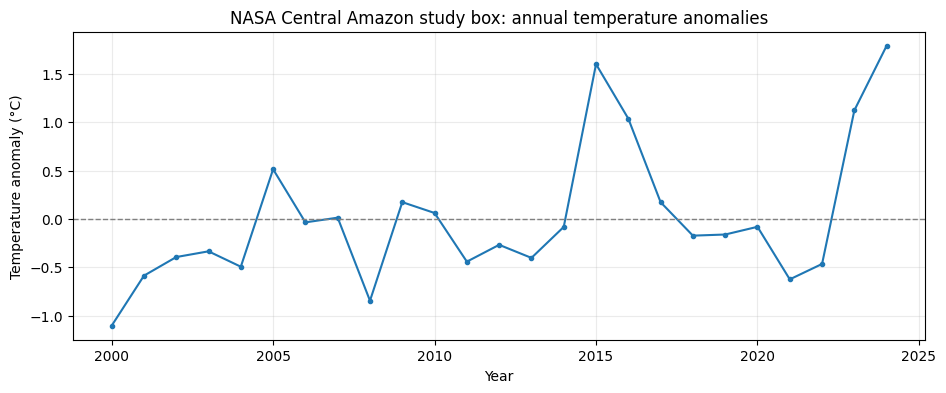

In [ ]:
import matplotlib.pyplot as plt
region_id='NASA_REGION_0001'
variable='T2M'
rows=service.observations(region_id,variable,2000,2024)
valid=pd.DataFrame([r for r in rows if r['value'] is not None])
if valid.empty:
    print('No NASA observations cached for this selection.')
else:
    valid['date']=pd.to_datetime(valid['date'])
    valid['month']=valid['date'].dt.month
    valid['anomaly']=valid['value']-valid.groupby('month')['value'].transform('mean')
    annual=valid.groupby(valid['date'].dt.year)['anomaly'].mean()
    plt.figure(figsize=(11,4))
    plt.plot(annual.index,annual.values,marker='o',markersize=3)
    plt.axhline(0,color='grey',linestyle='--',linewidth=1)
    plt.title('NASA Central Amazon study box: annual temperature anomalies')
    plt.xlabel('Year');plt.ylabel('Temperature anomaly (°C)');plt.grid(alpha=0.25)
    plt.show()

## 13. Run the backend tests

These tests check the code's behaviour using controlled examples: geospatial aggregation, data conversions, database caching, trend statistics, and API responses. They are valuable regression checks, but they do **not** replace live NASA retrieval or scientific validation of actual observations.

In [ ]:
%%writefile /content/active_future_labs/test_backend.py
import json
from pathlib import Path
from tempfile import TemporaryDirectory
from unittest.mock import Mock

import numpy as np
import pandas as pd

import backend as m

REG = dict(region_id='NASA_REGION_0001',region_label='Amazon test',west=-61.02,east=-59.02,south=-4.1,north=-2.1)


def test_geojson_parse():
    values={'200001':24.0,'200002':26.0}
    p={'features':[{'geometry':{'type':'Point','coordinates':[-60,-3]},'properties':{'parameter':{'T2M':values}}},
                   {'geometry':{'type':'Point','coordinates':[-59.5,-3.5]},'properties':{'parameter':{'T2M':{'200001':26.0,'200002':28.0}}}}]}
    rows=m._parse_power_geojson(p,'T2M',2000,2000)
    assert len(rows)==12
    assert 24<rows[0][1]<26
    assert rows[0][2:]==(2,2)
    assert rows[-1][1] is None


def test_point_fallback_and_label():
    class R:
        def __init__(self,url,params):
            self.ok = '/point' in url
            self.status_code=200 if self.ok else 422
            self.text='NASA rejected regional bounding box'
            self.params=params
        def json(self):
            return {'properties':{'parameter':{v:{f'{yy}{mm:02d}':20.0+i for yy in [2000] for mm in range(1,13)}
                                               for i,v in enumerate(m.POWER)}}}
    class S:
        def __init__(self):self.calls=[]
        def get(self,url,params,timeout):
            self.calls.append((url,params))
            return R(url,params)
    s=S()
    rows,metadata=m.retrieve_power(REG,2000,2000,session=s)
    assert len(rows)==4*12
    assert len(s.calls)==10  # one rejected regional + nine point calls
    assert all(r[-2]=='nine_point_area_sample_approximation' for r in rows)
    assert abs(rows[0][3]-20.0)<1e-10
    assert metadata['regional_error']


def test_sqlite_and_stats():
    with TemporaryDirectory() as d:
        service=m.Service(Path(d)/'data.sqlite3')
        service.seed_regions([REG])
        assert len(service.regions())==1
        rows=[]
        for i,dt in enumerate(m.date_range(2000,2024)):
            y=12+0.07*i/12+np.sin(i/12*2*np.pi)
            rows.append((REG['region_id'],'T2M',dt.strftime('%Y-%m-%d'),y,5,5,'native_grid_area_weighted','NASA POWER'))
        service._insert(rows)
        result=service.fit_trend(REG['region_id'],'T2M',2000,2024)
        assert result['status']=='preliminary_trend'
        assert abs(result['trend_per_decade']-0.7)<0.001
        assert result['ci95'][0]<=result['trend_per_decade']<=result['ci95'][1]
        all_=service.recompute_trends()
        assert all_['fitted']==1
        cached=service.cached_trend(REG['region_id'],'T2M',2000,2024)
        assert cached['p_bh'] is not None
        dest=service.backup(Path(d)/'backup.sqlite3')
        assert Path(dest).exists()


def test_spatial_aggregation_and_missing():
    regs=[REG,dict(region_id='elsewhere',west=0,east=2,south=0,north=2)]
    arr=np.array([[1.0,3.0],[2.0,-9999.]])
    out=m.spatial_aggregate(arr,np.array([-3.5,-2.5]),np.array([-60.5,-59.5]),regs)
    assert 1<out[REG['region_id']][0]<3
    assert out[REG['region_id']][1]==3
    assert out['elsewhere']==(None,0,0)


def test_gldas_units_from_netcdf():
    import xarray as xr
    with TemporaryDirectory() as d:
        ds=xr.Dataset({
            'SoilMoi0_10cm_inst':(('time','lat','lon'),np.full((1,2,2),20.)),
            'Evap_tavg':(('time','lat','lon'),np.full((1,2,2),1/86400)),
            'Qs_acc':(('time','lat','lon'),np.full((1,2,2),2.))
        },coords={'time':[pd.Timestamp('2000-01-01')], 'lat':[-3.5,-2.5], 'lon':[-60.5,-59.5]})
        fn=Path(d)/'test.nc'
        ds.to_netcdf(fn)
        got=m.extract_granule(fn,'gldas',[REG])
        assert abs(got['soil_moisture'][REG['region_id']][0]-20)<1e-10
        assert abs(got['evaporation'][REG['region_id']][0]-1)<1e-8
        assert abs(got['runoff'][REG['region_id']][0]-16)<1e-10


def test_api():
    from fastapi.testclient import TestClient
    with TemporaryDirectory() as d:
        service=m.Service(Path(d)/'test.sqlite')
        service.seed_regions([REG])
        app=m.make_app(service)
        client=TestClient(app)
        assert client.get('/health').status_code==200
        assert len(client.get('/api/variables').json()['variables'])==10
        assert len(client.get('/api/regions').json()['regions'])==1
        assert client.get('/api/trend',params={'region':REG['region_id'],'variable':'T2M'}).json()['status']=='insufficient_data'
        assert client.get('/api/observations',params={'region':'BAD','variable':'T2M'}).status_code==400


def test_power_padding_preserves_original_geometry():
    class FakeResponse:
        ok=True
        status_code=200
        def __init__(self,params):self.params=params
        def json(self):
            variable=self.params['parameters']
            period={f'2000{m:02d}':20.0 for m in range(1,13)}
            extra={f'2000{m:02d}':500.0 for m in range(1,13)}
            return {'features':[
                {'geometry':{'type':'Point','coordinates':[-60,-3]},
                 'properties':{'parameter':{variable:period}}},
                # deliberately outside original box but INSIDE the padded request
                {'geometry':{'type':'Point','coordinates':[-61.06,-3]},
                 'properties':{'parameter':{variable:extra}}}
            ]}
    class FakeSession:
        def __init__(self):self.calls=[]
        def get(self,url,params,timeout):
            self.calls.append((url,params))
            return FakeResponse(params)
    client=FakeSession()
    records,info=m.retrieve_power(REG,2000,2000,session=client)
    assert info['method']=='native_grid_center_weighted'
    assert len(client.calls)==4
    assert all(p['latitude-max']-p['latitude-min']>2 for _,p in client.calls)
    assert all(row[3]==20 and row[4]==1 and row[5]==1 for row in records)


def test_api_diagnostics_and_data_quality():
    from fastapi.testclient import TestClient
    with TemporaryDirectory() as tmp:
        service=m.Service(Path(tmp)/'main.sqlite')
        service.seed_regions([REG])
        rows=[]
        rng=np.random.default_rng(123)
        for i,dt in enumerate(m.date_range(2000,2024)):
            rows.append((REG['region_id'],'T2M',dt.strftime('%Y-%m-%d'),
                         25.0+0.15*i/12+2*np.sin(i*np.pi/6)+float(rng.normal(0,0.7)),
                         4,4,'native_grid_center_weighted','NASA POWER'))
        service._insert(rows)
        r=service.fit_trend(REG['region_id'],'T2M')
        assert r['status']=='preliminary_trend'
        assert r['diagnostics']['annual_theil_sen']['years_used']==25
        assert 0<=r['diagnostics']['residual_ljung_box_12_p']<=1
        assert 0<=r['diagnostics']['hac24_p']<=1
        assert service.source_progress()['all_requests_accounted_for'] is False
        a=service.recompute_trends()
        assert a['fitted']==1 and not a['multiple_testing_final_for_synced_collection']
        assert service.cached_trend(REG['region_id'],'T2M',2000,2024)['diagnostics']['hac24_ci95']
        client=TestClient(m.make_app(service))
        assert len(client.get('/api/quality').json()['report'])==1
        assert client.get('/api/trend',params={'region':REG['region_id'],'variable':'T2M'}).json()['diagnostics']


def test_constant_temperature_avoids_invalid_pvalues():
    with TemporaryDirectory() as tmp:
        service=m.Service(Path(tmp)/'data.sqlite')
        service.seed_regions([REG])
        service._insert([(REG['region_id'],'GWETTOP',d.strftime('%Y-%m-%d'),0,2,2,
                          'native_grid_center_weighted','NASA POWER')
                         for d in m.date_range(2000,2024)])
        result=service.fit_trend(REG['region_id'],'GWETTOP')
        assert result['status']=='constant_series'

Writing /content/active_future_labs/test_backend.py


In [ ]:
import subprocess
check = subprocess.run(['python','-m','pytest','-q',str(PROJECT/'test_backend.py')],
                       cwd=str(PROJECT),check=False)
if check.returncode != 0:
    raise RuntimeError('Backend offline tests failed. Review the errors before frontend integration.')
print('Backend offline tests passed.')

Backend offline tests passed.


## 14. Start the FastAPI server

The frontend will call this API to list study areas, request time series, and display trend estimates, confidence intervals and p-values. It reads cached NASA observations from SQLite; **visiting a page will not trigger a new historical download or an Earthdata login**.

Colab can run the server for development, but its runtime eventually disconnects. A public website needs a deployed backend with persistent database storage.

In [ ]:
import threading
import time
import requests
import uvicorn

# If this cell is rerun, stop the earlier server before reloading the app.
# Otherwise the frontend could unknowingly receive responses from old code.
old_server = globals().get('_nasa_server', globals().get('server'))
old_thread = globals().get('_nasa_server_thread', globals().get('thread'))
if isinstance(old_server, uvicorn.Server):
    old_server.should_exit = True
    if isinstance(old_thread, threading.Thread):
        old_thread.join(timeout=10)

API_LOCAL = 'http://127.0.0.1:8000'
try:
    old_response = requests.get(API_LOCAL + '/health', timeout=2)
    if old_response.ok:
        raise RuntimeError(
            'Port 8000 still has another server running. '
            'Restart the Colab runtime and run the notebook from the top.'
        )
except requests.exceptions.RequestException:
    pass

app = backend.make_app(service)
_nasa_server = uvicorn.Server(uvicorn.Config(
    app, host='0.0.0.0', port=8000, log_level='warning'
))
_nasa_server_thread = threading.Thread(target=_nasa_server.run, daemon=True)
_nasa_server_thread.start()

# The API can take a moment to finish starting up.
for _ in range(40):
    try:
        health = requests.get(API_LOCAL + '/health', timeout=2)
        if health.ok:
            break
    except requests.exceptions.RequestException:
        pass
    time.sleep(0.5)
else:
    raise RuntimeError('FastAPI did not start. Inspect the notebook output above.')

print('Backend:', health.json())
status = requests.get(API_LOCAL + '/api/status', timeout=10).json()
print('NASA source progress:', json.dumps(status['source_progress'], indent=2))
print('API documentation:', API_LOCAL + '/docs')

try:
    from google.colab.output import eval_js
    print('Colab browser URL:', eval_js('google.colab.kernel.proxyPort(8000)'))
except Exception as error:
    print('Colab browser proxy not available:', error)

Backend: {'status': 'running', 'data_origin': 'NASA APIs only', 'cache': 'SQLite'}
NASA source progress: {
  "power_complete_regions": 360,
  "expected_regions": 360,
  "earthdata": {
    "gldas": {
      "complete_months": 300,
      "missing_months": 0,
      "expected_months": 300
    },
    "imerg": {
      "complete_months": 300,
      "missing_months": 0,
      "expected_months": 300
    },
    "aerosol": {
      "complete_months": 300,
      "missing_months": 0,
      "expected_months": 300
    }
  },
  "all_requests_accounted_for": true
}
API documentation: http://127.0.0.1:8000/docs
Colab browser URL: https://8000-m-s-use1d11-118zf7fa4qxty-d.us-east1.prod.r.colab.dev


## 15. Connect the frontend during development

For a separate website, you can optionally create a temporary HTTPS URL with ngrok. Your frontend teammate can call the FastAPI endpoints through that URL.

An ngrok tunnel is **public to anyone with its address** and lasts only as long as the Colab runtime is active. Keep it disabled until you need an external connection, and never paste the ngrok token into your notebook or GitHub.

In [ ]:
ENABLE_NGROK = False

if ENABLE_NGROK:
    from getpass import getpass
    from pyngrok import ngrok

    # The token is entered at runtime rather than written into project files.
    token = getpass('Enter your ngrok authtoken: ')
    ngrok.set_auth_token(token)
    tunnel = ngrok.connect(8000, 'http')
    print('Frontend API base URL:', tunnel.public_url)
    print('API docs:', tunnel.public_url + '/docs')
else:
    print('Tunnel is disabled. Use the Colab proxy for local testing.')

Tunnel is disabled. Use the Colab proxy for local testing.


## Frontend handoff

Frontend teammate can connect to the API using the URLs below. The endpoints return JSON with study-area boundaries, NASA data coverage, monthly observations and statistical results.

```javascript
const API_BASE = "https://YOUR-DEPLOYED-BACKEND";

const regions = await fetch(`${API_BASE}/api/regions`).then(r => r.json());
const variables = await fetch(`${API_BASE}/api/variables`).then(r => r.json());
const status = await fetch(`${API_BASE}/api/status`).then(r => r.json());
const observations = await fetch(`${API_BASE}/api/observations?region=NASA_REGION_0001&variable=T2M`).then(r => r.json());
const trend = await fetch(`${API_BASE}/api/trend?region=NASA_REGION_0001&variable=T2M`).then(r => r.json());
```

Other endpoints include `/api/geojson`, `/api/coverage`, `/api/quality`, `/api/trends`, `/api/compare` and `/api/relationships`. Open `/docs` on the running API to see the accepted query parameters.

**Before the final demo:** check `/api/status` and `/api/quality`, review model diagnostics, and distinguish real regional grid means from nine-point approximations. Not all areas will have complete coverage for every NASA product. If the judges need a live website, move FastAPI and its SQLite database to persistent hosting; Colab alone cannot provide that.

**NASA documentation:** [POWER Monthly API](https://power.larc.nasa.gov/docs/services/api/temporal/monthly/) · [earthaccess authentication](https://earthaccess.readthedocs.io/en/stable/user/explanation/authenticate/)